# **Milestone 4**

In [46]:

import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from scipy.stats import skew
from xgboost import XGBClassifier

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, confusion_matrix, f1_score,
    fbeta_score, precision_score, recall_score, roc_auc_score
)
from sklearn.model_selection import (
    GridSearchCV, RandomizedSearchCV, StratifiedGroupKFold, StratifiedKFold,
    cross_val_predict, cross_val_score, cross_validate
)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

In [3]:
from google.colab import drive

drive.mount('/content/drive')

PATH = "/content/drive/MyDrive/DS_project/model_df.parquet"
print("File exists:", os.path.exists(PATH))
model_df = pd.read_parquet(PATH)

INFRA_COLS = ["s2bq11", "s5m1q10", "s5m2q01", "s5m2q10"]
print("model_df shape:", model_df.shape)
print("Infra columns missing:", [c for c in INFRA_COLS if c not in model_df.columns])
print("\nTarget Variable (out_of_school) Distribution:")
print(model_df["out_of_school"].value_counts(dropna=False))

Mounted at /content/drive
File exists: True
model_df shape: (25237, 267)
Infra columns missing: []

Target Variable (out_of_school) Distribution:
out_of_school
0.0    16534
1.0     8703
Name: count, dtype: int64


###**Following are the cells from milestone 3 required in milestone 4**

**PART A: BASELINE MODEL IMPLEMENTATION (Naive Benchmark + Logistic Regression + Decision Tree)**

In [4]:
# ------------------------------------------------------------
# 1. Prepare Features, Target and Household Groups
# ------------------------------------------------------------

# Remove observations with missing schooling outcomes
model_df = model_df.dropna(subset=["out_of_school"]).copy()

# Define predictor variables
NUM_FEATURES = [
    "s1aq51", "hh_size", "wealth_index",
    "mom_age", "mom_age_gap"
]

BIN_FEATURES = ["rural", "mom_employed"]

CAT_FEATURES = ["mom_educ_level", "province"]

FEATURES = NUM_FEATURES + BIN_FEATURES + CAT_FEATURES

# Prepare features
X = model_df[FEATURES].copy()

# Convert numeric and binary columns to float
for c in NUM_FEATURES + BIN_FEATURES:
    X[c] = pd.to_numeric(X[c], errors="coerce").astype(float)

# Convert categorical columns to object
for c in CAT_FEATURES:
    X[c] = X[c].astype(object).where(X[c].notna(), np.nan)

# Define target variable
y = model_df["out_of_school"].astype(int)

# Create household groups
groups = (
    model_df["prcode"].astype(str) + "_" +
    model_df["hhno"].astype(str)
)

print("Total observations:", len(X))
print("Total features:", X.shape[1])
print("Out-of-school percentage:", round(y.mean() * 100, 2))

print("\nMissing values in features:")
print(X.isna().sum()[X.isna().sum() > 0])

# ------------------------------------------------------------
# 2. Define Preprocessing Pipeline
# ------------------------------------------------------------

preprocess = ColumnTransformer([
    (
        "num",
        Pipeline([
            ("imp", SimpleImputer(
                strategy="median",
                add_indicator=True
            )),
            ("sc", StandardScaler())
        ]),
        NUM_FEATURES
    ),
    (
        "bin",
        SimpleImputer(strategy="most_frequent"),
        BIN_FEATURES
    ),
    (
        "cat",
        Pipeline([
            ("imp", SimpleImputer(
                strategy="constant",
                fill_value="missing"
            )),
            ("ohe", OneHotEncoder(
                handle_unknown="ignore"
            ))
        ]),
        CAT_FEATURES
    )
])
# ------------------------------------------------------------
# 3. Define Baseline Models
# ------------------------------------------------------------

models = {
    "Majority Class (naive)": DummyClassifier(
        strategy="most_frequent"
    ),

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=50,
        random_state=42
    )
}

# ------------------------------------------------------------
# 4. Create Model Pipelines
# ------------------------------------------------------------

model_pipelines = {
    name: Pipeline([
        ("prep", preprocess),
        ("clf", model)
    ])
    for name, model in models.items()
}

print("\nBaseline models initialized successfully!")

for name in model_pipelines:
    print("-", name)


Total observations: 25237
Total features: 9
Out-of-school percentage: 34.49

Missing values in features:
mom_age           911
mom_age_gap       911
mom_employed      915
mom_educ_level    982
dtype: int64

Baseline models initialized successfully!
- Majority Class (naive)
- Logistic Regression
- Decision Tree


In [5]:

# ============================================================
# PART B - : MODELING DATA PREPARATION
# ============================================================

# Create a separate modeling copy of our girls' dataset
model_data = model_df.copy()

# Target: 1 = out of school, 0 = enrolled
target_col = "out_of_school"

# Predictor variables from our research
# Use the same predictors as Part A
feature_cols = [
    "s1aq51",
    "hh_size",
    "wealth_index",
    "mom_age",
    "mom_age_gap",
    "rural",
    "mom_employed",
    "mom_educ_level",
    "province"
]

# Verify all necessary columns exist
required_cols = (
    feature_cols +
    [target_col, "prcode", "hhno"]
)

missing_cols = [
    col for col in required_cols
    if col not in model_data.columns
]

assert not missing_cols, (
    f"Missing columns: {missing_cols}"
)

# Keep observations with a valid target
model_data = model_data.dropna(
    subset=[target_col]
).copy()

# Prepare inputs and outputs
X = model_data[feature_cols].copy()
y = model_data[target_col].astype(int)

# Create a household identifier to prevent
# sisters from appearing in different data splits
groups = (
    model_data["prcode"].astype(str) + "_" +
    model_data["hhno"].astype(str)
)

print("Total observations:", len(X))
print("Total predictors:", X.shape[1])
print("Unique households:", groups.nunique())

print("\nTarget distribution (%):")
print((y.value_counts(normalize=True) * 100).round(2))


Total observations: 25237
Total predictors: 9
Unique households: 14841

Target distribution (%):
out_of_school
0    65.51
1    34.49
Name: proportion, dtype: float64


In [6]:

# PART B - STEP 2: TRAIN-TEST SPLIT (80/20)

from sklearn.model_selection import StratifiedGroupKFold

# Split data into 80% training and 20% testing
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

train_idx, test_idx = next(splitter.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

groups_train = groups.iloc[train_idx]
groups_test = groups.iloc[test_idx]

print("Training:", len(train_idx) / len(X) * 100, "%")
print("Testing:", len(test_idx) / len(X) * 100, "%")

# Check the split
print("Training size:", len(X_train))
print("Testing size:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True).round(3))

# Check for household overlap
assert set(groups_train).isdisjoint(set(groups_test))
print("\nNo household overlap — split successful!")


Training: 80.21951896025676 %
Testing: 19.780481039743233 %
Training size: 20245
Testing size: 4992

Training class distribution:
out_of_school
0    0.655
1    0.345
Name: proportion, dtype: float64

Testing class distribution:
out_of_school
0    0.657
1    0.343
Name: proportion, dtype: float64

No household overlap — split successful!


In [7]:

# PART B - STEP 3: 5-FOLD CROSS-VALIDATION

from sklearn.model_selection import StratifiedGroupKFold, cross_validate

# Create 5 folds within the training dataset
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = {}

# Evaluate all three baseline models from Part A
for name, pipeline in model_pipelines.items():

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        groups=groups_train,
        cv=cv,
        scoring="accuracy"
    )

    cv_results[name] = scores["test_score"]

    print(f"\n{name}")
    print("Accuracy per fold:", scores["test_score"].round(3))
    print("Mean accuracy:", round(scores["test_score"].mean(), 3))
    print("Standard deviation:", round(scores["test_score"].std(), 3))



Majority Class (naive)
Accuracy per fold: [0.646 0.655 0.651 0.672 0.649]
Mean accuracy: 0.655
Standard deviation: 0.009

Logistic Regression
Accuracy per fold: [0.734 0.746 0.726 0.736 0.738]
Mean accuracy: 0.736
Standard deviation: 0.006

Decision Tree
Accuracy per fold: [0.738 0.73  0.713 0.726 0.728]
Mean accuracy: 0.727
Standard deviation: 0.008


In [8]:

# PART B - STEP 4: HYPERPARAMETER TUNING

from sklearn.model_selection import GridSearchCV

# Define hyperparameter values to test
param_grids = {
    "Logistic Regression": {
        "clf__C": [0.01, 0.1, 1, 10]
    },
    "Decision Tree": {
        "clf__max_depth": [3, 5, 8, 12],
        "clf__min_samples_leaf": [20, 50, 100]
    }
}

best_models = {}

# Tune each machine learning model
for name, params in param_grids.items():

    grid = GridSearchCV(
        estimator=model_pipelines[name],
        param_grid=params,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1
    )

    grid.fit(X_train, y_train, groups=groups_train)

    best_models[name] = grid.best_estimator_

    print(f"\n{name}")
    print("Best parameters:", grid.best_params_)
    print("Best ROC-AUC:", round(grid.best_score_, 3))



Logistic Regression
Best parameters: {'clf__C': 1}
Best ROC-AUC: 0.798

Decision Tree
Best parameters: {'clf__max_depth': 8, 'clf__min_samples_leaf': 50}
Best ROC-AUC: 0.794


**Milestone 3 — Part C: Performance Evaluation and Error Analysis**

In [9]:
# PART C - STEP 1: PERFORMANCE EVALUATION
# Use tuned ML models and the original naive benchmark
final_models = {
    "Majority Class": model_pipelines["Majority Class (naive)"],
    "Logistic Regression": best_models["Logistic Regression"],
    "Decision Tree": best_models["Decision Tree"]}
evaluation_results = []
predictions = {}
for name, model in final_models.items():
    # Train on the training data
    model.fit(X_train, y_train)

    # Predict on the untouched test data
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    predictions[name] = y_pred

    # Calculate confusion matrix values
    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    # Calculate all six metrics
    evaluation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "Specificity": tn / (tn + fp),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

# Display results
evaluation_df = pd.DataFrame(evaluation_results)
print(evaluation_df.round(3).to_string(index=False))



              Model  Accuracy  Precision  Recall  Specificity  F1-Score  ROC-AUC
     Majority Class     0.657      0.000   0.000        1.000     0.000    0.500
Logistic Regression     0.747      0.653   0.560        0.845     0.603    0.808
      Decision Tree     0.746      0.640   0.591        0.827     0.614    0.809


# **MILESTONE 4**

**Milestone 4 — Part A: Advanced Modelling**

**Infrastructure variables (Z).** Three household infrastructure variables were added: electricity (has_electricity), main drinking-water source (water_group) and toilet type (toilet_group). Water labels were grouped into improved, unimproved and surface; toilet labels into improved, unimproved and none. Labels that fit no rule stay in "other/unmapped" (water: "others (specify..)", 117 girls; toilet: "others (specify--)", 176 girls, and "composting toilet", 51 girls). The cross-tabulations were checked to confirm that each raw label landed in the intended group. As a leakage check, each variable was used alone to predict out-of-school status with five-fold grouped cross-validation. All were weak predictors (single-variable ROC-AUC: electricity 0.628, toilet type 0.618, water source 0.512), so none acts as a proxy for the target, unlike s2bq11. Road access was not added to the model.

In [10]:
# MILESTONE 4 — STEP 0: INFRASTRUCTURE VARIABLES (Z)
from sklearn.model_selection import cross_val_score

req = ["s2bq11", "s5m1q10", "s5m2q01", "s5m2q10"]
assert not [c for c in req if c not in model_data.columns], "Missing infrastructure columns"

# 1) Proof that distance to school cannot be used
display(pd.crosstab(model_data["s2bq11"].astype(str).eq("Not Attending"),
                    model_data["out_of_school"],
                    rownames=["s2bq11 == 'Not Attending'"], colnames=["out_of_school"]))

# 2) Electricity (and road access)
model_data["has_electricity"] = np.where(
    model_data["s5m1q10"].isna(), np.nan,
    model_data["s5m1q10"].astype(str).str.lower().str.contains("electricity").astype(float))
if "s5m1q15a" in model_data.columns:
    model_data["all_season_road"] = (model_data["s5m1q15a"].astype(str).str.strip()
                                     .str.lower().map({"yes": 1.0, "no": 0.0}))

# 3) Grouped water and toilet variables.
def group_label(series, rules, default="other/unmapped"):
    s = series.astype("string").str.strip().str.lower()
    out = pd.Series(default, index=series.index, dtype="object")
    done = pd.Series(False, index=series.index)
    for label, pats in rules:
        hit = s.str.contains("|".join(pats), regex=True, na=False) & ~done
        out[hit] = label
        done |= hit
    out[series.isna()] = np.nan
    return out

WATER_RULES = [
    ("surface",    [r"river", r"canal", r"stream", r"pond", r"lake", r"surface"]),
    ("unimproved", [r"open well", r"unprotected", r"tanker", r"vendor", r"cart", r"^other$"]),
    ("improved",   [r"tap", r"pipe", r"pump", r"tube ?well", r"bore", r"closed well",
                    r"protected", r"spring", r"bottle", r"mineral", r"filtration"]),
]
TOILET_RULES = [
    ("none",       [r"no toilet", r"^none$", r"open (field|defecation)", r"bush"]),
    ("improved",   [r"flush", r"septic", r"sewer"]),
    ("unimproved", [r"latrine", r"dry", r"pit", r"bucket", r"hanging", r"^other$"]),
]

for raw, new, rules in [("s5m2q01", "water_group", WATER_RULES),
                        ("s5m2q10", "toilet_group", TOILET_RULES)]:
    model_data[new] = group_label(model_data[raw], rules)
    display(pd.crosstab(model_data[raw].astype(str), model_data[new].astype(str)))   # CHECK THIS TABLE
    share = (model_data[new] == "other/unmapped").mean()
    if share > 0.02:
        print(f"WARNING: {share:.1%} of {new} is unmapped - add those labels to the rules above")

INFRA_NUM = []
INFRA_BIN = ["has_electricity"]
INFRA_CAT = ["water_group", "toilet_group"]

# 4) Leakage guard: each infrastructure variable alone should be a weak predictor
cv_leak = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for c in INFRA_BIN + INFRA_CAT:
    p = Pipeline([("oh", OneHotEncoder(handle_unknown="ignore")),
                  ("lr", LogisticRegression(max_iter=1000))])
    xc = model_data.iloc[train_idx][[c]].astype(str)
    auc = cross_val_score(p, xc, y_train, groups=groups_train, cv=cv_leak, scoring="roc_auc").mean()
    rows.append({"variable": c, "single-variable AUC": auc})
leak_df = pd.DataFrame(rows)
display(leak_df.round(3))
assert (leak_df["single-variable AUC"] < 0.90).all(), "A variable still leaks the target"

out_of_school,0.0,1.0
s2bq11 == 'Not Attending',,
False,16534,0
True,0,8703


water_group,improved,other/unmapped,surface,unimproved
s5m2q01,,,,
bore hole(motor pump)/tube well,6694,0,0,0
bottled water,464,0,0,0
closed well,253,0,0,0
closed well (2),58,0,0,0
filtration plant,1459,0,0,0
hand pump,4231,0,0,0
hand pump (2),2355,0,0,0
motorized pumping/tube well,1210,0,0,0
open well,0,0,0,133


/tmp/ipykernel_632/1358172631.py:26: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  hit = s.str.contains("|".join(pats), regex=True, na=False) & ~done


toilet_group,improved,none,other/unmapped,unimproved
s5m2q10,,,,
others (specify--),0,0,176,0
composting toilet,0,0,51,0
dry pit latrine,0,0,0,1082
dry raised latrine,0,0,0,441
flush connected to open drain,5531,0,0,0
flush connected to pit,5164,0,0,0
flush connected to public sewerage,4881,0,0,0
flush connected to spectic tank,5390,0,0,0
no toilet,0,2521,0,0


,variable,single-variable AUC
0,has_electricity,0.628
1,water_group,0.512
2,toilet_group,0.618


**Distance to school (s2bq11) was excluded.** We initially considered using the "distance to school" variable from the HIES dataset, but the cross-tabulation above shows that it cannot be used. The value "Not Attending" appears for all 8,703 out-of-school girls and for none of the 16,534 enrolled girls, so the variable is recorded only for girls who currently attend school. It therefore encodes the target itself (target leakage) and would give any model a perfect but meaningless prediction. It also says nothing about the distance that keeps girls from enrolling in the first place, because it is missing for girls who never attended. Instead, we use infrastructure variables that are recorded for every household: electricity, main drinking-water source and toilet type.

In [11]:
# MILESTONE 4 — NEW FEATURE SET (X2) AND PREPROCESSOR
NUM2 = [c for c in NUM_FEATURES if c != "mom_age_gap"] + INFRA_NUM
BIN2 = BIN_FEATURES + INFRA_BIN
CAT2 = CAT_FEATURES + INFRA_CAT
FEATURES2 = NUM2 + BIN2 + CAT2

assert not set(["s2bq11", "distance_to_school"]) & set(FEATURES2), "leaky variable in features"
assert len(FEATURES2) == len(set(FEATURES2)), "duplicate feature"

X2 = model_data[FEATURES2].copy()
for c in NUM2 + BIN2:
    X2[c] = pd.to_numeric(X2[c], errors="coerce").astype(float)
for c in CAT2:
    X2[c] = X2[c].astype(object).map(lambda v: str(v).strip() if pd.notna(v) else np.nan).astype(object)

X2_train, X2_test = X2.iloc[train_idx], X2.iloc[test_idx]
assert X2_train.index.equals(X_train.index) and X2_test.index.equals(X_test.index)

preprocess2 = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                      ("sc", StandardScaler())]), NUM2),
    ("bin", SimpleImputer(strategy="most_frequent"), BIN2),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="missing")),
                      ("ohe", OneHotEncoder(handle_unknown="ignore"))]), CAT2),
])

# Milestone 4 models (RF, NN)
M4_NAMES = {"Random Forest", "Neural Network"}
def X_tr(name): return X2_train if name in M4_NAMES else X_train
def X_te(name): return X2_test if name in M4_NAMES else X_test

print("Milestone 4 feature set:", len(FEATURES2), "predictors ->", FEATURES2)

Milestone 4 feature set: 11 predictors -> ['s1aq51', 'hh_size', 'wealth_index', 'mom_age', 'rural', 'mom_employed', 'has_electricity', 'mom_educ_level', 'province', 'water_group', 'toilet_group']


The Milestone 4 feature set has 11 predictors: the nine Milestone 3 predictors without mom_age_gap, plus electricity, water group and toilet group. mom_age_gap was dropped because it is a linear combination of the girl's age and the mother's age, so it adds no new information and makes the inputs redundant. The preprocessing is the same as in Milestone 3 (median imputation with missing-value indicators and scaling for numeric variables, most-frequent imputation for binary variables, a "missing" category and one-hot encoding for categorical variables). The same household-grouped train/test split is reused, so all models are evaluated on identical girls. The Milestone 3 baselines keep their original 9-variable feature set, while the Random Forest and Neural Network use the 11-variable set.

**Random Forest.** A Random Forest averages many decision trees trained on random samples of girls and random subsets of predictors. It can capture non-linear effects and interactions (for example, wealth mattering differently by province) that Logistic Regression cannot, and it is more stable than a single Decision Tree. The initial settings (100 trees, maximum depth 8, at least 10 samples per leaf) are a moderate starting point, tuned below.

In [12]:
# MILESTONE 4 — PART A: RANDOM FOREST CLASSIFIER
# Define the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=8,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

# Combine preprocessing and model
rf_pipeline = Pipeline([
    ("prep", preprocess2),
    ("clf", rf_model)
])

# Train using only the training dataset
rf_pipeline.fit(X2_train, y_train)

print("Number of trees:", rf_model.n_estimators)
print("Maximum depth:", rf_model.max_depth)
print("Minimum samples per leaf:", rf_model.min_samples_leaf)


Number of trees: 100
Maximum depth: 8
Minimum samples per leaf: 10


In [13]:
# RANDOM FOREST — INITIAL CROSS-VALIDATION
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_validate(
    rf_pipeline,
    X2_train,
    y_train,
    groups=groups_train,
    cv=cv,
    scoring=["accuracy", "recall", "f1", "roc_auc"],
    n_jobs=-1
)

print("Random Forest — Initial CV Results")

for metric in ["accuracy", "recall", "f1", "roc_auc"]:
    values = scores[f"test_{metric}"]
    print(f"{metric}: {values.mean():.3f} ± {values.std():.3f}")


Random Forest — Initial CV Results
accuracy: 0.754 ± 0.007
recall: 0.512 ± 0.013
f1: 0.589 ± 0.014
roc_auc: 0.818 ± 0.006


When evaluated with five-fold Stratified Group Cross-Validation on the training data, the initial Random Forest (100 trees, maximum depth 8, at least 10 samples per leaf) achieved an accuracy of 75.4% (± 0.007), a recall of 51.2% (± 0.013), an F1-score of 0.589 (± 0.014) and a ROC-AUC of 0.818 (± 0.006). The low standard deviations indicate consistent performance across folds. The Random Forest has higher cross-validated accuracy than the best Milestone 3 baseline (Logistic Regression, 73.6%). However, part of this gain may come from the infrastructure variables added in Milestone 4 rather than from the algorithm itself. Its recall shows that about 49% of out-of-school girls are still missed at the default 0.5 threshold.

In [14]:

# MILESTONE 4 — RANDOM FOREST HYPERPARAMETER TUNING

# Parameters to explore
rf_params = {
    "clf__n_estimators": [100, 200, 300],
    "clf__max_depth": [5, 8, 12, None],
    "clf__min_samples_leaf": [5, 10, 20, 50],
    "clf__max_features": ["sqrt", "log2"]
}

# Use the same 5-fold grouped cross-validation
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Search for the best parameter combination
rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_params,
    n_iter=15,
    cv=cv,
    scoring="roc_auc",
    random_state=42,
    n_jobs=-1
)

# Tune using training data only
rf_search.fit(X2_train, y_train, groups=groups_train)

# Save the best fitted model
best_rf = rf_search.best_estimator_

print("Best Random Forest parameters:")
print(rf_search.best_params_)

print("\nBest CV ROC-AUC:", round(rf_search.best_score_, 3))


Best Random Forest parameters:
{'clf__n_estimators': 300, 'clf__min_samples_leaf': 20, 'clf__max_features': 'sqrt', 'clf__max_depth': None}

Best CV ROC-AUC: 0.821


RandomizedSearchCV (15 random combinations out of 96 possible, five-fold Stratified Group Cross-Validation, scored by ROC-AUC) was used to tune the Random Forest on the training data.

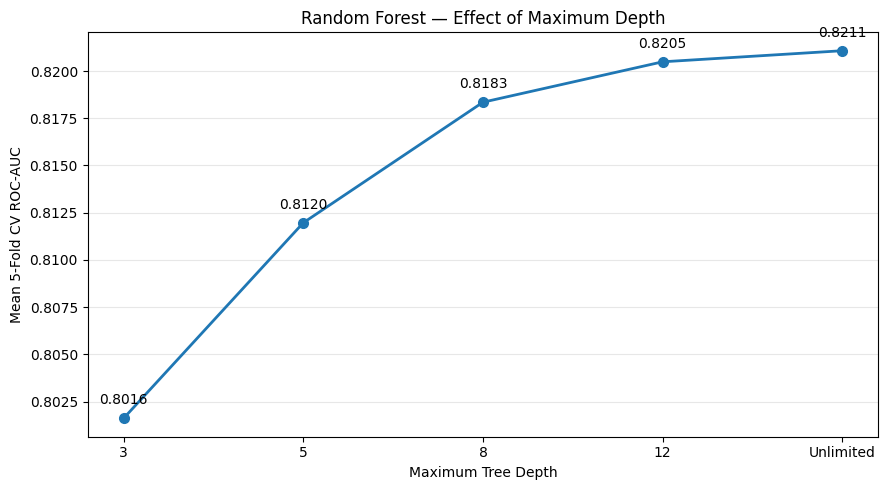

,Depth,ROC-AUC
0,3,0.8016
1,5,0.8120
2,8,0.8183
3,12,0.8205
4,Unlimited,0.8211


In [15]:
# Five-fold grouped cross-validation
cv_depth = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Test different maximum depths
depth_results = []

for depth in [3, 5, 8, 12, None]:
    model = clone(best_rf)
    model.set_params(clf__max_depth=depth)

    scores = cross_val_score(
        model,
        X2_train,
        y_train,
        groups=groups_train,
        cv=cv_depth,
        scoring="roc_auc",
        n_jobs=2
    )

    depth_results.append({
        "Depth": "Unlimited" if depth is None else str(depth),
        "ROC-AUC": scores.mean()
    })

depth_df = pd.DataFrame(depth_results)

# Plot line graph
plt.figure(figsize=(9, 5))

plt.plot(
    depth_df["Depth"],
    depth_df["ROC-AUC"],
    marker="o",
    linewidth=2,
    markersize=7
)

# Show ROC-AUC value above each point
for i, score in enumerate(depth_df["ROC-AUC"]):
    plt.annotate(
        f"{score:.4f}",
        (i, score),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        fontsize=10
    )

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Mean 5-Fold CV ROC-AUC")
plt.title("Random Forest — Effect of Maximum Depth")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

display(depth_df.round(4))


The line plot shows the cross-validated ROC-AUC of the tuned Random Forest at different maximum depths (all other parameters fixed at the tuned values). ROC-AUC rises from 0.802 at depth 3 to 0.812 at depth 5, 0.818 at depth 8 and 0.8205 at depth 12, then levels off at 0.821 with unlimited depth. Shallow trees underfit, and gains beyond depth 8 are very small (under 0.003). This agrees with the search, which selected max_depth = None, and with the conclusion that tuning matters much less than the information in the features.

In [16]:
# GROUPED vs NON-GROUPED SPLITTING: WHAT HAPPENS IF SISTERS ARE SEPARATED?

scoring = ["accuracy", "recall", "f1", "roc_auc"]

# 1) How many test girls have a sister in train under a random split?
rand_tr, rand_te = next(StratifiedKFold(5, shuffle=True, random_state=42).split(X, y))
shared = set(groups.iloc[rand_tr]) & set(groups.iloc[rand_te])
print(f"Random split: {len(shared)} households appear in BOTH train and test")
print(f"Test girls with a sister in train: {groups.iloc[rand_te].isin(shared).mean():.1%}")

# 2) Same models, same data, same 5 folds: only the splitter differs
models = {
    "Logistic Regression": (best_models["Logistic Regression"], X),
    "Decision Tree":       (best_models["Decision Tree"], X),
    "Random Forest":       (rf_pipeline, X2),
}
splitters = {
    "Random (sisters split)":     StratifiedKFold(5, shuffle=True, random_state=42),
    "Grouped (sisters together)": StratifiedGroupKFold(5, shuffle=True, random_state=42),
}

rows = []
for mname, (model, Xm) in models.items():
    for sname, cv_ in splitters.items():
        s = cross_validate(model, Xm, y, groups=groups, cv=cv_, scoring=scoring, n_jobs=-1)
        rows.append({"Model": mname, "Split": sname,
                     **{m: s[f"test_{m}"].mean() for m in scoring}})

leak_df = pd.DataFrame(rows)
print(leak_df.round(3).to_string(index=False))

# Inflation = random minus grouped
piv = leak_df.pivot(index="Model", columns="Split", values="roc_auc")
print("\nROC-AUC inflation from ignoring households:")
print((piv["Random (sisters split)"] - piv["Grouped (sisters together)"]).round(3))

Random split: 2714 households appear in BOTH train and test
Test girls with a sister in train: 60.9%


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:877: UserWarning: The groups parameter is ignored by StratifiedKFold
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:877: UserWarning: The groups parameter is ignored by StratifiedKFold
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:877: UserWarning: The groups parameter is ignored by StratifiedKFold
  warnings.warn(


              Model                      Split  accuracy  recall    f1  roc_auc
Logistic Regression     Random (sisters split)     0.740   0.551 0.594    0.800
Logistic Regression Grouped (sisters together)     0.740   0.550 0.594    0.800
      Decision Tree     Random (sisters split)     0.740   0.569 0.600    0.800
      Decision Tree Grouped (sisters together)     0.737   0.574 0.601    0.798
      Random Forest     Random (sisters split)     0.760   0.530 0.604    0.824
      Random Forest Grouped (sisters together)     0.757   0.525 0.599    0.821

ROC-AUC inflation from ignoring households:
Model
Decision Tree          0.002
Logistic Regression    0.000
Random Forest          0.003
dtype: float64


**Effect of household grouping**. To test whether keeping sisters together matters, we repeated 5-fold CV with a random stratified split that ignores households. Under this split, 2,714 households appeared in both training and test folds, and 60.9% of test girls had a sister in the training data. Even so, performance was almost identical to the grouped split: ROC-AUC differed by 0.000 (Logistic Regression), 0.002 (Decision Tree) and 0.003 (Random Forest), within fold-to-fold variation (SD about 0.006). So household leakage is negligible for our models. This is because our predictors are household-level and our models are regularised and depth-limited, so they cannot memorise individual households. We still keep grouped splits because (1) sisters are not independent observations, so a random split is methodologically invalid even when its numerical effect is small, and (2) it guarantees that results reflect performance on unseen households, the real deployment setting. The grouped split also protects against leakage in more flexible models, which could memorise household patterns.

**Neural Network (MLP).** A multi-layer perceptron learns non-linear combinations of the predictors through hidden layers. The initial network has two hidden layers (64 and 32 neurons) with ReLU activation, the Adam optimiser and a small L2 penalty (alpha = 0.001). Inputs are scaled by the shared preprocessing step, which neural networks need.

In [17]:

# MILESTONE 4 — PART A: NEURAL NETWORK (MLP)

# Define the Neural Network
nn_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    alpha=0.001,
    learning_rate_init=0.001,
    max_iter=500,
    random_state=42
)

# Combine preprocessing and Neural Network
nn_pipeline = Pipeline([
    ("prep", preprocess2),
    ("clf", nn_model)
])

# Train on training data only
nn_pipeline.fit(X2_train, y_train)

print("Hidden layers:", nn_model.hidden_layer_sizes)
print("Iterations completed:", nn_model.n_iter_)


Hidden layers: (64, 32)
Iterations completed: 359


In [18]:

# NEURAL NETWORK — INITIAL CROSS-VALIDATION
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_validate(
    nn_pipeline,
    X2_train,
    y_train,
    groups=groups_train,
    cv=cv,
    scoring=["accuracy", "recall", "f1", "roc_auc"],
    n_jobs=-1
)

print("Neural Network — Initial CV Results")

for metric in ["accuracy", "recall", "f1", "roc_auc"]:
    values = scores[f"test_{metric}"]
    print(f"{metric}: {values.mean():.3f} ± {values.std():.3f}")


Neural Network — Initial CV Results
accuracy: 0.728 ± 0.007
recall: 0.590 ± 0.036
f1: 0.599 ± 0.021
roc_auc: 0.779 ± 0.009


The Neural Network model, when evaluated using five-fold Stratified Group Cross-Validation on the training dataset, achieved an accuracy of 72.8%. Similarly, recall was 59.0%, F1-score was 0.599, and ROC-AUC was 0.779. The standard deviations were relatively low for accuracy (0.007), F1-score (0.021), and ROC-AUC (0.009), indicating reasonably consistent performance across folds, although recall showed greater variation (0.036). The recall of 59.0% indicates that the model correctly identified approximately 59% of out-of-school girls while missing around 41%. Although the ROC-AUC of 0.779 suggests a reasonable ability to distinguish between enrolled and out-of-school girls, the relatively high proportion of missed cases remains an important limitation.

In [19]:

# NEURAL NETWORK — FASTER HYPERPARAMETER TUNING

from sklearn.model_selection import RandomizedSearchCV, StratifiedGroupKFold
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline

nn_fast = MLPClassifier(
    solver="adam",
    max_iter=200,
    early_stopping=False,
    n_iter_no_change=10,
    random_state=42
)


nn_fast_pipeline = Pipeline([
    ("prep", preprocess2),
    ("clf", nn_fast)
])

# Smaller search space
nn_params = {
    "clf__hidden_layer_sizes": [(32,), (64,), (64, 32)],
    "clf__alpha": [0.001, 0.01],
    "clf__learning_rate_init": [0.001, 0.005]
}

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

nn_search = RandomizedSearchCV(
    estimator=nn_fast_pipeline,
    param_distributions=nn_params,
    n_iter=6,
    cv=cv,
    scoring="roc_auc",
    random_state=42,
    n_jobs=2,
    refit=True,
    verbose=1
)

nn_search.fit(X2_train, y_train, groups=groups_train)

best_nn = nn_search.best_estimator_

print("\nBest Neural Network parameters:")
print(nn_search.best_params_)

print("\nBest CV ROC-AUC:", round(nn_search.best_score_, 3))


Fitting 5 folds for each of 6 candidates, totalling 30 fits

Best Neural Network parameters:
{'clf__learning_rate_init': 0.001, 'clf__hidden_layer_sizes': (32,), 'clf__alpha': 0.001}

Best CV ROC-AUC: 0.817


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


RandomizedSearchCV (6 of the 12 possible combinations of architecture, alpha and learning rate; five-fold Stratified Group Cross-Validation; scored by ROC-AUC) was used to tune the Neural Network on the training data. To keep the search fast, the maximum number of iterations was lowered to 200, and some fits reached that limit without fully converging (sklearn ConvergenceWarning). The best configuration used one hidden layer with 32 neurons, alpha = 0.001 and an initial learning rate of 0.001. It reached a cross-validated ROC-AUC of 0.817, compared with 0.779 for the initial network. The improvement suggests that a smaller network generalises better here. Final performance is assessed on the held-out test set below.

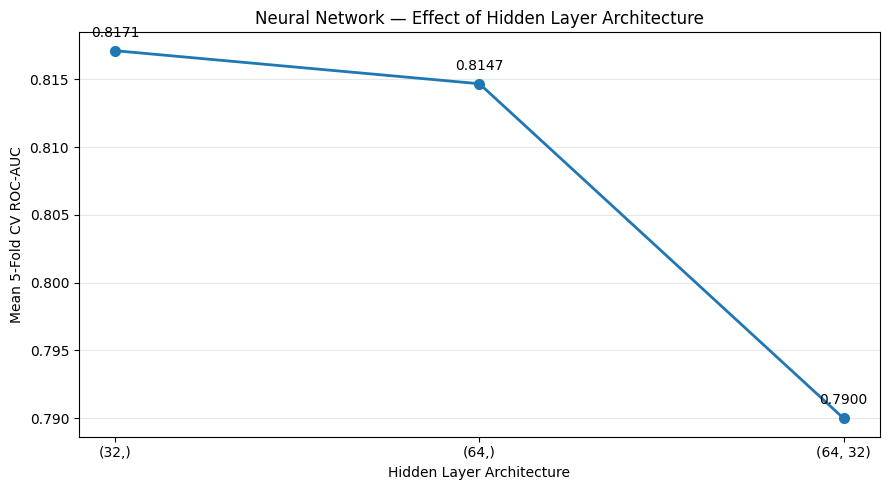

,Architecture,ROC-AUC
0,"(32,)",0.8171
1,"(64,)",0.8147
2,"(64, 32)",0.7900


In [20]:
# Five-fold grouped cross-validation
cv_nn = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Test different Neural Network architectures
architectures = [(32,), (64,), (64, 32)]
architecture_results = []

for architecture in architectures:
    model = clone(best_nn)
    model.set_params(
        clf__hidden_layer_sizes=architecture
    )

    scores = cross_val_score(
        model,
        X2_train,
        y_train,
        groups=groups_train,
        cv=cv_nn,
        scoring="roc_auc",
        n_jobs=2
    )

    architecture_results.append({
        "Architecture": str(architecture),
        "ROC-AUC": scores.mean()
    })

architecture_df = pd.DataFrame(architecture_results)

# Plot line graph
plt.figure(figsize=(9, 5))

plt.plot(
    architecture_df["Architecture"],
    architecture_df["ROC-AUC"],
    marker="o",
    linewidth=2,
    markersize=7
)

# Display ROC-AUC above each point
for i, score in enumerate(architecture_df["ROC-AUC"]):
    plt.annotate(
        f"{score:.4f}",
        (i, score),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        fontsize=10
    )

plt.xlabel("Hidden Layer Architecture")
plt.ylabel("Mean 5-Fold CV ROC-AUC")
plt.title("Neural Network — Effect of Hidden Layer Architecture")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

display(architecture_df.round(4))


In [21]:

# MILESTONE 4 — FINAL MODEL BENCHMARKING
# Reuse the Milestone 3 baselines and tuned Milestone 4 models
benchmark_models = {
    "Majority Class": final_models["Majority Class"],
    "Logistic Regression": best_models["Logistic Regression"],
    "Decision Tree": best_models["Decision Tree"],
    "Random Forest": best_rf,
    "Neural Network": best_nn
}

benchmark_results = []

for name, model in benchmark_models.items():

    # Predictions on the same test set
    Xt = X_te(name)
    y_pred = model.predict(Xt)
    y_prob = model.predict_proba(Xt)[:, 1]

    benchmark_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC (AP)": average_precision_score(y_test, y_prob)
    })

benchmark_df = pd.DataFrame(benchmark_results)

display(benchmark_df.round(3))


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC (AP)
0,Majority Class,0.657,0.000,0.000,0.000,0.500,0.343
1,Logistic Regression,0.747,0.653,0.560,0.603,0.808,0.659
2,Decision Tree,0.746,0.640,0.591,0.614,0.809,0.657
3,Random Forest,0.768,0.703,0.562,0.625,0.830,0.716
4,Neural Network,0.766,0.677,0.608,0.641,0.828,0.715


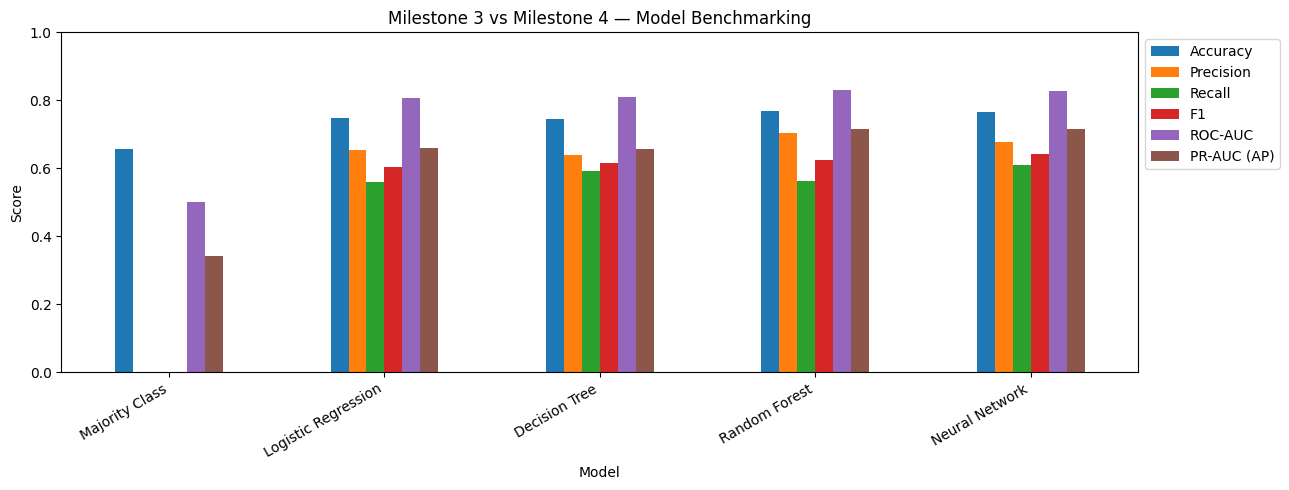

In [22]:

# VISUAL COMPARISON OF ALL FIVE MODELS
metrics = [
    "Accuracy", "Precision", "Recall",
    "F1", "ROC-AUC", "PR-AUC (AP)"
]

ax = benchmark_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(13, 5),
    ylim=(0, 1)
)

plt.title("Milestone 3 vs Milestone 4 — Model Benchmarking")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=30, ha="right")
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()


The tuned Random Forest and Neural Network were benchmarked against the three Milestone 3 baselines on the same held-out test set (4,992 girls).

Random Forest achieved the highest accuracy (76.8%), precision (70.3%), ROC-AUC (0.830) and PR-AUC (0.716). Its recall (56.2%) is about the same as Logistic Regression (56.0%) and lower than the Decision Tree (59.1%). The Neural Network achieved the highest recall (60.8%) and F1-score (0.641), with accuracy 76.6%, precision 67.7%, ROC-AUC 0.828 and PR-AUC 0.715. The Majority Class Classifier reached 65.7% accuracy but zero precision, recall and F1, which shows why accuracy alone is misleading.

Overall, the Random Forest is best at ranking girls and at precision, and the Neural Network is best at finding out-of-school girls. Even so, every model still misses about 39% to 44% of out-of-school girls at the default 0.5 threshold, which motivates the imbalance-aware models below.

In [23]:
# MILESTONE 4 — COMPARATIVE PERFORMANCE GAINS
metrics = [
    "Accuracy", "Precision", "Recall",
    "F1", "ROC-AUC", "PR-AUC (AP)"
]

# Use Logistic Regression as the baseline
baseline = benchmark_df.set_index("Model").loc["Logistic Regression", metrics]

# Calculate changes in each metric
gains_df = (
    benchmark_df.set_index("Model")[metrics]
    .loc[["Random Forest", "Neural Network"]]
    .subtract(baseline)
    .multiply(100)
)

gains_df.index.name = "Advanced Model"

print("Performance gains vs Logistic Regression (percentage points):")
display(gains_df.round(2))


Performance gains vs Logistic Regression (percentage points):


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC (AP)
Advanced Model,,,,,,
Random Forest,2.12,4.97,0.23,2.18,2.26,5.68
Neural Network,1.92,2.43,4.85,3.81,2.04,5.55


The tuned Random Forest and Neural Network were compared against Logistic Regression, the strongest Milestone 3 baseline by cross-validation accuracy, using six metrics on the held-out test set (percentage-point change).

Random Forest: accuracy +2.12, precision +4.97, recall +0.23, F1 +2.18, ROC-AUC +2.26, PR-AUC +5.68.
Neural Network: accuracy +1.92, precision +2.43, recall +4.85, F1 +3.81, ROC-AUC +2.04, PR-AUC +5.55.

Both advanced models improved on Logistic Regression on every metric. The Random Forest gains most in precision and PR-AUC, and the Neural Network gains most in recall and F1, which makes it the more relevant model for finding out-of-school girls. The gains are modest (a few points) and come from a single test split without confidence intervals. Part of them may also come from the added infrastructure variables rather than the algorithm (see the ablation below).

In [24]:
pos_w = (y_train == 0).sum() / (y_train == 1).sum()
rf_best = {k.replace("clf__", ""): v for k, v in rf_search.best_params_.items()}
lr_C = best_models["Logistic Regression"].named_steps["clf"].C

models_v2 = {
    "LR (balanced)": LogisticRegression(C=lr_C, class_weight="balanced",
                                        max_iter=1000, random_state=42),
    "RF (balanced)": RandomForestClassifier(**rf_best, class_weight="balanced",
                                            random_state=42, n_jobs=-1),
    "XGBoost (weighted)": XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                                        subsample=0.8, colsample_bytree=0.8,
                                        scale_pos_weight=pos_w, eval_metric="logloss",
                                        random_state=42, n_jobs=-1),
}
cv2 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

oof_v2, fitted_v2 = {}, {}
for name, clf in models_v2.items():
    pipe = Pipeline([("prep", preprocess2), ("clf", clf)])
    oof_v2[name] = cross_val_predict(pipe, X2_train, y_train, groups=groups_train,
                                     cv=cv2, method="predict_proba", n_jobs=-1)[:, 1]
    fitted_v2[name] = pipe.fit(X2_train, y_train)
    print(f"{name:20s} OOF ROC-AUC = {roc_auc_score(y_train, oof_v2[name]):.3f} | "
          f"OOF recall @0.5 = {recall_score(y_train, oof_v2[name] >= 0.5):.3f}")

LR (balanced)        OOF ROC-AUC = 0.811 | OOF recall @0.5 = 0.773
RF (balanced)        OOF ROC-AUC = 0.821 | OOF recall @0.5 = 0.781
XGBoost (weighted)   OOF ROC-AUC = 0.824 | OOF recall @0.5 = 0.752


In [25]:

CAND_THR = np.linspace(0.05, 0.60, 56)

def pick_threshold(y, p, beta=2):
    return CAND_THR[int(np.argmax([fbeta_score(y, p >= t, beta=beta) for t in CAND_THR]))]

rows = []
for name, pipe in fitted_v2.items():
    thr = pick_threshold(y_train, oof_v2[name])
    oof_f2 = fbeta_score(y_train, oof_v2[name] >= thr, beta=2)
    p_te = pipe.predict_proba(X2_test)[:, 1]
    for label, t in [("0.50 (default)", 0.5), (f"{thr:.2f} (F2 on train folds)", thr)]:
        pred = (p_te >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
        rows.append({"Model": name, "Threshold": label,
                     "Accuracy": accuracy_score(y_test, pred),
                     "Precision": precision_score(y_test, pred, zero_division=0),
                     "Recall": recall_score(y_test, pred),
                     "F1": f1_score(y_test, pred),
                     "ROC-AUC": roc_auc_score(y_test, p_te),
                     "PR-AUC": average_precision_score(y_test, p_te),
                     "Missed (FN)": fn, "False alarms (FP)": fp,
                     "_thr": t, "_sel": oof_f2 if t != 0.5 else -1})
v2_df = pd.DataFrame(rows)
display(v2_df.drop(columns=["_thr", "_sel"]).round(3))

best_row = v2_df.sort_values("_sel", ascending=False).iloc[0]
FINAL_NAME, FINAL_THR = best_row["Model"], float(best_row["_thr"])
final_model_v2 = fitted_v2[FINAL_NAME]
print(f"Selected on training folds: {FINAL_NAME} at threshold {FINAL_THR:.2f}")

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Missed (FN),False alarms (FP)
0,LR (balanced),0.50 (default),0.736,0.586,0.784,0.671,0.820,0.701,370,946
1,LR (balanced),0.24 (F2 on train folds),0.603,0.461,0.953,0.622,0.820,0.701,80,1904
2,RF (balanced),0.50 (default),0.743,0.594,0.784,0.676,0.831,0.715,369,916
3,RF (balanced),0.28 (F2 on train folds),0.614,0.469,0.949,0.627,0.831,0.715,88,1840
4,XGBoost (weighted),0.50 (default),0.751,0.608,0.771,0.680,0.833,0.722,392,851
5,XGBoost (weighted),0.25 (F2 on train folds),0.622,0.474,0.938,0.630,0.833,0.722,106,1780


Selected on training folds: XGBoost (weighted) at threshold 0.25


To address the low recall found earlier, three imbalance-aware models were trained on the Milestone 4 feature set: Logistic Regression and Random Forest with class_weight="balanced" (using the tuned C and Random Forest parameters), and XGBoost with scale_pos_weight (enrolled girls ÷ out-of-school girls in the training data; 300 trees, depth 4, learning rate 0.05, not further tuned). Out-of-fold probabilities from five-fold grouped cross-validation on the training data were used to choose, for each model, the decision threshold (searched from 0.05 to 0.60) that maximises the F2-score, which weights recall twice as much as precision. This matches the aim of missing fewer out-of-school girls. The final model and threshold were selected on the training folds only (highest out-of-fold F2). The test set was used only to report results at the default 0.50 threshold and at the chosen threshold.

Out-of-fold ROC-AUC was 0.811 (Logistic Regression), 0.821 (Random Forest) and 0.824 (XGBoost). XGBoost was selected, with a threshold of 0.25. On the test set it catches 93.8% of out-of-school girls (106 missed, compared with roughly 670 for the Neural Network at 0.5), with precision 0.474, F1 0.630, ROC-AUC 0.833 and PR-AUC 0.722. The cost is 1,780 false alarms and a drop in accuracy to 0.622. Accuracy is therefore no longer the headline metric: the threshold deliberately trades precision and accuracy for recall. The other two models behave similarly (recall 0.95 at their chosen thresholds).

In [26]:
import statsmodels.formula.api as smf

d = model_data.iloc[train_idx].copy()
need = ["out_of_school", "mom_educ_level", "rural", "mom_employed", "s1aq51",
        "hh_size", "wealth_index", "mom_age", "province", "has_electricity"]
for c in ["out_of_school", "rural", "mom_employed", "s1aq51", "hh_size",
          "wealth_index", "mom_age", "has_electricity"]:
    d[c] = pd.to_numeric(d[c], errors="coerce").astype(float)
for c in ["water_group", "toilet_group"]:
    d[c] = d[c].fillna("missing")
d = d.dropna(subset=need)
hh_codes = pd.factorize(d["prcode"].astype(str) + "_" + d["hhno"].astype(str))[0]

formula = ('out_of_school ~ C(mom_educ_level, Treatment("none")) + rural + mom_employed'
           ' + s1aq51 + hh_size + wealth_index + mom_age + C(province, Treatment("punjab"))'
           ' + has_electricity + C(water_group) + C(toilet_group)'
           ' + C(mom_educ_level, Treatment("none")):rural + mom_employed:rural')


res = smf.logit(formula, data=d).fit(disp=0, cov_type="cluster", cov_kwds={"groups": hh_codes})

inter = [n for n in res.params.index if ":" in n]
ci = res.conf_int().loc[inter]
display(pd.DataFrame({"coef": res.params[inter], "odds_ratio": np.exp(res.params[inter]),
                      "CI_low": np.exp(ci[0]), "CI_high": np.exp(ci[1]),
                      "p": res.pvalues[inter]}).round(3))

def wald_p(names):
    R = np.zeros((len(names), len(res.params)))
    for i, n in enumerate(names):
        R[i, list(res.params.index).index(n)] = 1
    return float(res.wald_test(R, scalar=True).pvalue)

print(f"H2 (education x rural) joint Wald p = {wald_p([n for n in inter if 'mom_educ_level' in n]):.4f}")
print(f"H4 (employment x rural) Wald p      = {wald_p([n for n in inter if n.startswith('mom_employed')]):.4f}")
print("Girls used:", len(d), "| households:", len(set(hh_codes)))

,coef,odds_ratio,CI_low,CI_high,p
"C(mom_educ_level, Treatment(""none""))[T.primary]:rural",0.089,1.093,0.768,1.555,0.621
"C(mom_educ_level, Treatment(""none""))[T.middle]:rural",-0.196,0.822,0.530,1.275,0.380
"C(mom_educ_level, Treatment(""none""))[T.secondary]:rural",-0.409,0.664,0.398,1.110,0.118
"C(mom_educ_level, Treatment(""none""))[T.higher]:rural",0.373,1.452,0.814,2.588,0.206
mom_employed:rural,0.240,1.272,0.993,1.627,0.056


H2 (education x rural) joint Wald p = 0.2551
H4 (employment x rural) Wald p      = 0.0564
Girls used: 19453 | households: 11444


Hypotheses H2 (maternal education × rural) and H4 (maternal employment × rural) were tested with a logistic regression on the training data. It uses all Milestone 4 predictors plus the two interaction sets, with standard errors clustered by household because sisters share a household. H2 was tested with a joint Wald test across all four education-level interaction terms, and H4 with a Wald test on the employment × rural term. The model used 19,453 girls from 11,444 households (792 training girls with missing mother data or other missing predictors are dropped).

H2: joint Wald p = 0.255. No individual education × rural term is significant (p between 0.12 and 0.62). H4: Wald p = 0.056, odds ratio 1.27 (95% CI 0.99 to 1.63).

Both p-values are above 0.05, so there is no clear evidence at the 5% level that the effect of maternal education or maternal employment differs between rural and urban households. H4 is borderline: the estimate suggests the employment–out-of-school association is somewhat more positive in rural households, but the interval includes 1, so it should not be over-read. A non-significant result is not proof of no interaction, because the test may have limited power. These are associations, not causal effects.

In [27]:
# ABLATION: same XGBoost with vs without infrastructure variables (test set)
from sklearn.base import clone

def make_prep(num, bin_, cat):
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                          ("sc", StandardScaler())]), num),
        ("bin", SimpleImputer(strategy="most_frequent"), bin_),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="missing")),
                          ("ohe", OneHotEncoder(handle_unknown="ignore"))]), cat),
    ])

num0 = [c for c in NUM2 if c not in INFRA_NUM]
bin0 = [c for c in BIN2 if c not in INFRA_BIN]
cat0 = [c for c in CAT2 if c not in INFRA_CAT]

rows = []
for label, (n, b, ct) in {"without infrastructure": (num0, bin0, cat0),
                          "with infrastructure":    (NUM2, BIN2, CAT2)}.items():
    pipe = Pipeline([("prep", make_prep(n, b, ct)),
                     ("clf", clone(models_v2["XGBoost (weighted)"]))])
    pipe.fit(X2_train[n + b + ct], y_train)
    p = pipe.predict_proba(X2_test[n + b + ct])[:, 1]
    rows.append({"XGBoost": label, "ROC-AUC": roc_auc_score(y_test, p),
                 "PR-AUC": average_precision_score(y_test, p),
                 "Recall @0.5": recall_score(y_test, p >= 0.5)})
display(pd.DataFrame(rows).round(3))

,XGBoost,ROC-AUC,PR-AUC,Recall @0.5
0,without infrastructure,0.824,0.687,0.786
1,with infrastructure,0.833,0.722,0.771


Adding the infrastructure variables (electricity, drinking-water source and toilet type) raised the XGBoost ROC-AUC from 0.824 to 0.833 and the PR-AUC from 0.687 to 0.722, while recall at the 0.5 threshold fell slightly (0.786 without vs 0.771 with infrastructure). Infrastructure therefore improves how well girls are ranked by risk, but the gain is modest and it does not help catch more out-of-school girls at a fixed threshold. This is a single test split without confidence intervals. Road access was not included in the model. Distance to school could not be used, because it is recorded only for attending girls.

**Summary of all models (test set).** Baselines, Random Forest and Neural Network use the default 0.5 threshold; the final XGBoost model uses the 0.25 threshold chosen on training folds.

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC | PR-AUC |
|---|---|---|---|---|---|---|
| Majority Class | 0.657 | 0.000 | 0.000 | 0.000 | 0.500 | 0.343 |
| Logistic Regression | 0.747 | 0.653 | 0.560 | 0.603 | 0.808 | 0.659 |
| Decision Tree | 0.746 | 0.640 | 0.591 | 0.614 | 0.809 | 0.657 |
| Random Forest | 0.768 | 0.703 | 0.562 | 0.625 | 0.830 | 0.716 |
| Neural Network | 0.766 | 0.677 | 0.608 | 0.641 | 0.828 | 0.715 |
| XGBoost (weighted, threshold 0.25) | 0.622 | 0.474 | 0.938 | 0.630 | 0.833 | 0.722 |

Threshold-free metrics (ROC-AUC, PR-AUC) improve only slightly from the baselines to the final model. The large change in recall comes from class weighting and the lower threshold, not from a better ranking of girls.

**MILESTONE 4 — ALGORITHMIC BIAS AND FAIRNESS AUDIT**

**Sensitive attributes.** The audit covers the characteristics along which girls' access to schooling in Pakistan is unequal, and on which the model's errors could also be unequal:

- **Area** (rural / urban) and **province** (geographic disadvantage)
- **Wealth quintile** (socio-economic class)
- **Age group** (<=9, 10-12, 13+), included because the Milestone 3 edge-case analysis showed that younger girls were missed more often
- **Mother data** (linked / not linked), which is not a social identity, but these girls are handled only through imputation, so it checks whether the model is less reliable for them

Area, province, wealth and age are also model inputs, so the model is not "blind" to them; the audit therefore checks outcomes, not inputs. The positive prediction is "flagged as out of school", which here leads to support (enrolment drive or stipend). The reference group for each attribute is the group with the lowest actual out-of-school rate. It is a comparison baseline, not a claim that the group is advantaged; for example, many girls aged 9 or under may simply not have started school yet. Because the baseline is chosen by need, "gap vs reference" can understate or overstate unfairness, so the ranges (highest minus lowest group) are used alongside it. The 80% rule is applied in both directions: a group passes if its flag rate is between 80% and 125% of the reference group's.

Because groups differ genuinely in need, flagging disadvantaged groups more often is expected, so demographic parity alone is not the target. Equal opportunity (equal TPR) and predictive equality (equal FPR) are the main criteria.

In [28]:
# ============================================================
# MILESTONE 4 — FAIRNESS AUDIT, STEP 1: SENSITIVE ATTRIBUTES
# ============================================================

# Trained (non-naive) models to audit; LR and DT were fitted on X_train, RF and NN on X2_train
audit_models = {
    "Logistic Regression": best_models["Logistic Regression"],
    "Decision Tree":       best_models["Decision Tree"],
    "Random Forest":       best_rf,
    "Neural Network":      best_nn,
}
PRIMARY_MODEL = "Neural Network"
THRESHOLD     = 0.5
MIN_N         = 50                 # smallest group treated as reliable

# Protected / sensitive attributes (built from the original, un-imputed data)
def build_sensitive(X_part):
    raw = model_data.loc[X_part.index]
    s = pd.DataFrame(index=X_part.index)
    s["Area"] = np.where(X_part["rural"].isna(), "Unknown",
                         np.where(X_part["rural"] == 1, "Rural", "Urban"))
    s["Province"] = (X_part["province"].astype(str).str.strip().str.lower()
                     .str.title().replace({"Kp": "KP", "Nan": "Unknown"}))
    s["Wealth quintile"] = raw["wealth_quintile"].astype(str).replace({"nan": "Unknown"})
    s["Age group"] = (pd.cut(X_part["s1aq51"], bins=[-np.inf, 9, 12, np.inf],
                             labels=["<=9", "10-12", "13+"])
                      .astype(str).replace({"nan": "Unknown"}))
    s["Mother data"] = np.where(X_part["mom_educ_level"].isna(),
                                "No mother data", "Mother data linked")
    return s

SENSITIVE = ["Area", "Province", "Wealth quintile", "Age group", "Mother data"]

s_train = build_sensitive(X_train)
s_test  = build_sensitive(X_test)

# One audit table: sensitive attributes + truth + each model's probability and prediction
audit = s_test.copy()
audit["y_true"] = y_test.values
for name, mdl in audit_models.items():
    prob = mdl.predict_proba(X_te(name))[:, 1]
    audit[f"prob_{name}"] = prob
    audit[f"pred_{name}"] = (prob >= THRESHOLD).astype(int)

# Group sizes and actual out-of-school rates per sensitive attribute
for attr in SENSITIVE:
    t = (audit.groupby(attr)["y_true"]
         .agg(n="size", out_of_school_rate="mean").round(3))
    print(f"\n{attr}\n{t.to_string()}")

# Reference ("privileged") group = least-disadvantaged group, i.e. the group with the
# lowest actual out-of-school rate (among groups with n >= MIN_N). Override if you wish.
REF_OVERRIDE = {}   # e.g. {"Area": "Urban", "Province": "Punjab"}
REF = {}
for attr in SENSITIVE:
    t = audit.groupby(attr)["y_true"].agg(["size", "mean"])
    t = t[(t["size"] >= MIN_N) & (t.index != "Unknown")]
    REF[attr] = REF_OVERRIDE.get(attr, t["mean"].idxmin())
print("\nReference (privileged) groups:", REF)


Area
          n  out_of_school_rate
Area                           
Rural  3340               0.407
Urban  1652               0.213

Province
                n  out_of_school_rate
Province                             
Balochistan   607               0.555
KP           1055               0.297
Punjab       1995               0.214
Sindh        1335               0.476

Wealth quintile
                    n  out_of_school_rate
Wealth quintile                          
Q1 - Lowest      1009               0.448
Q2               1089               0.445
Q3               1083               0.344
Q4                946               0.233
Q5 - Highest      865               0.209

Age group
              n  out_of_school_rate
Age group                          
10-12      1255               0.302
13+        1656               0.448
<=9        2081               0.284

Mother data
                       n  out_of_school_rate
Mother data                                 
Mother data linked  480

In [29]:
# ============================================================
# STEP 2: HELPER — PER-GROUP METRICS
# ============================================================
def _div(a, b):
    return a / b if b > 0 else np.nan

def group_rates(d, pred_col):
    y, p = d["y_true"].values, d[pred_col].values
    tp = int(((y == 1) & (p == 1)).sum()); fn = int(((y == 1) & (p == 0)).sum())
    fp = int(((y == 0) & (p == 1)).sum()); tn = int(((y == 0) & (p == 0)).sum())
    return pd.Series({
        "n": len(d), "actual_rate": y.mean(), "selection_rate": p.mean(),
        "TPR": _div(tp, tp + fn), "FPR": _div(fp, fp + tn),
        "precision": _div(tp, tp + fp), "accuracy": (tp + tn) / len(d),
        "FN": fn, "FP": fp,
    })

def group_table(attr, model_name=None):
    model_name = model_name or PRIMARY_MODEL
    pred_col = f"pred_{model_name}"
    t = pd.DataFrame({g: group_rates(d, pred_col)
                      for g, d in audit.groupby(attr)}).T
    t[["n", "FN", "FP"]] = t[["n", "FN", "FP"]].astype(int)
    return t

**Demographic parity / disparate impact**

Demographic parity — Neural Network (threshold = 0.5)


,Attribute,Group,n,Reference,Actual out-of-school rate,Flag rate,DI ratio vs ref,Parity diff vs ref,80% rule
0,Area,Rural,3340,,0.407,0.385,2.534,0.233,FAIL
1,Area,Urban,1652,yes,0.213,0.152,1.000,0.000,Pass
2,Province,Balochistan,607,,0.555,0.534,4.111,0.404,FAIL
3,Province,KP,1055,,0.297,0.235,1.811,0.105,FAIL
4,Province,Punjab,1995,yes,0.214,0.130,1.000,0.000,Pass
5,Province,Sindh,1335,,0.476,0.529,4.073,0.399,FAIL
6,Wealth quintile,Q1 - Lowest,1009,,0.448,0.456,3.155,0.311,FAIL
7,Wealth quintile,Q2,1089,,0.445,0.444,3.069,0.299,FAIL
8,Wealth quintile,Q3,1083,,0.344,0.292,2.019,0.147,FAIL
9,Wealth quintile,Q4,946,,0.233,0.162,1.119,0.017,Pass


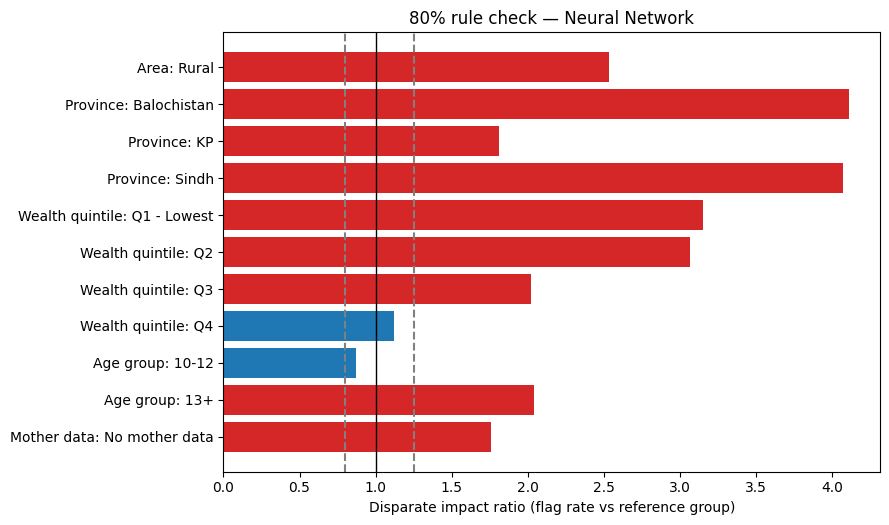

In [30]:
# ============================================================
# STEP 3: DEMOGRAPHIC PARITY / DISPARATE IMPACT (80% rule)
# ============================================================
# Positive prediction = girl flagged as out of school.
# DI = flag rate of group / flag rate of reference group.
# 80% rule: pass if 0.80 <= DI <= 1.25 (lower rate is at least 80% of the higher one).
dp_rows = []
for attr in SENSITIVE:
    t = group_table(attr)
    ref_rate = t.loc[REF[attr], "selection_rate"]
    for g, r in t.iterrows():
        di = r["selection_rate"] / ref_rate if ref_rate > 0 else np.nan
        dp_rows.append({
            "Attribute": attr, "Group": g, "n": int(r["n"]),
            "Reference": "yes" if g == REF[attr] else "",
            "Actual out-of-school rate": r["actual_rate"],
            "Flag rate": r["selection_rate"],
            "DI ratio vs ref": di,
            "Parity diff vs ref": r["selection_rate"] - ref_rate,
            "80% rule": ("n too small" if r["n"] < MIN_N
                         else "Pass" if 0.8 <= di <= 1.25 else "FAIL"),
        })
dp_df = pd.DataFrame(dp_rows)
print(f"Demographic parity — {PRIMARY_MODEL} (threshold = {THRESHOLD})")
display(dp_df.round(3))

# Plot: DI ratio per group, with the 80% / 125% limits
plot_df = dp_df[(dp_df["Reference"] == "") & (dp_df["Group"] != "Unknown")
                & (dp_df["n"] >= MIN_N)].copy()
plot_df["label"] = plot_df["Attribute"] + ": " + plot_df["Group"].astype(str)
fig, ax = plt.subplots(figsize=(9, 0.35 * len(plot_df) + 1.5))
colors = np.where(plot_df["80% rule"] == "Pass", "tab:blue", "tab:red")
ax.barh(plot_df["label"], plot_df["DI ratio vs ref"], color=colors)
ax.axvline(1.0, color="black", lw=1)
ax.axvline(0.8, color="gray", ls="--"); ax.axvline(1.25, color="gray", ls="--")
ax.set_xlabel("Disparate impact ratio (flag rate vs reference group)")
ax.set_title(f"80% rule check — {PRIMARY_MODEL}")
ax.invert_yaxis(); plt.tight_layout(); plt.show()

**Interpretation.** Nine of the sixteen groups (nine of the eleven non-reference groups) fail the 80% rule, all on the high side (flagged more than 1.25 times as often as the reference group): rural girls (DI 2.53), Balochistan (4.11), KP (1.81), Sindh (4.07), the bottom three wealth quintiles (Q1 3.16, Q2 3.07, Q3 2.02), ages 13+ (2.04), and girls with no mother data (1.76). Only ages 10-12 (0.87) and Q4 (1.12) pass besides the reference groups, and Q4's bootstrap interval (0.86 to 1.50) includes 1.

Much of this is expected, because these groups have a higher out-of-school rate and the model uses that information. But need does not explain all of it. The DI is larger than the ratio of actual rates (rural 2.53 vs 1.91, Sindh 4.07 vs 2.22, Balochistan 4.11 vs 2.59, Q1 3.16 vs 2.14). The reason is that the reference groups are under-flagged: urban girls are flagged at 0.15 against an actual rate of 0.21, Punjab at 0.13 against 0.21, and Q5 at 0.15 against 0.21. Rural girls and Balochistan are flagged at roughly their actual rate (0.39 vs 0.41 and 0.53 vs 0.56), and Sindh slightly above it (0.53 vs 0.48). The disparity therefore comes mainly from low-need groups being missed, not from high-need groups being over-flagged. Demographic parity is not the right target here because it would ignore genuine differences in need, and the equal opportunity results below are the more informative measure.

**Equalized odds / equal opportunity**

Equalized odds / equal opportunity — Neural Network


,Attribute,Group,n,Reference,TPR,FPR,TPR gap vs ref,FPR gap vs ref,Missed girls (FN)
0,Area,Rural,3340,,0.655,0.200,0.226,0.123,469
1,Area,Urban,1652,yes,0.429,0.077,0.000,0.000,201
2,Province,Balochistan,607,,0.697,0.330,0.279,0.278,102
3,Province,KP,1055,,0.450,0.144,0.033,0.093,172
4,Province,Punjab,1995,yes,0.418,0.052,0.000,0.000,248
5,Province,Sindh,1335,,0.767,0.313,0.349,0.261,148
6,Wealth quintile,Q1 - Lowest,1009,,0.732,0.232,0.279,0.169,121
7,Wealth quintile,Q2,1089,,0.676,0.257,0.223,0.194,157
8,Wealth quintile,Q3,1083,,0.531,0.166,0.078,0.103,175
9,Wealth quintile,Q4,946,,0.464,0.070,0.011,0.007,118



Summary per attribute


,Attribute,Model,TPR range (equal opp. gap),FPR range,Equalized-odds gap (max),Min/Max flag-rate ratio,Overall accuracy
0,Area,Neural Network,0.226,0.123,0.226,0.395,0.766
1,Province,Neural Network,0.349,0.278,0.349,0.243,0.766
2,Wealth quintile,Neural Network,0.279,0.194,0.279,0.317,0.766
3,Age group,Neural Network,0.300,0.157,0.300,0.428,0.766
4,Mother data,Neural Network,0.161,0.160,0.161,0.569,0.766


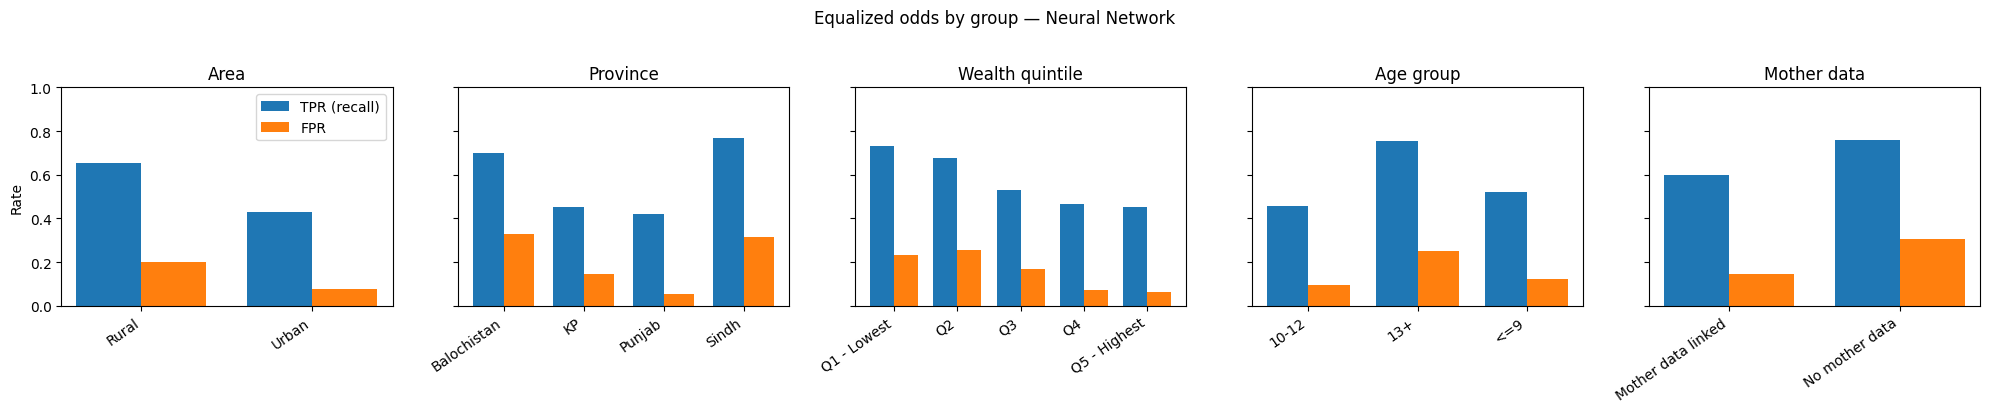

In [31]:
# ============================================================
# STEP 4: EQUALIZED ODDS / EQUAL OPPORTUNITY (TPR and FPR across groups)
# ============================================================

# Equalized odds: equal TPR AND equal FPR.
eo_rows = []
for attr in SENSITIVE:
    t = group_table(attr)
    ref = t.loc[REF[attr]]
    for g, r in t.iterrows():
        eo_rows.append({
            "Attribute": attr, "Group": g, "n": int(r["n"]),
            "Reference": "yes" if g == REF[attr] else "",
            "TPR": r["TPR"], "FPR": r["FPR"],
            "TPR gap vs ref": r["TPR"] - ref["TPR"],
            "FPR gap vs ref": r["FPR"] - ref["FPR"],
            "Missed girls (FN)": int(r["FN"]),
        })
eo_df = pd.DataFrame(eo_rows)
print(f"Equalized odds / equal opportunity — {PRIMARY_MODEL}")
display(eo_df.round(3))

# One-line summary per attribute: spread of TPR and FPR across reliable groups
def attr_summary(attr, model_name):
    t = group_table(attr, model_name)
    t = t[(t["n"] >= MIN_N) & (t.index != "Unknown")]
    tpr_rng = t["TPR"].max() - t["TPR"].min()
    fpr_rng = t["FPR"].max() - t["FPR"].min()
    sel = t["selection_rate"]
    return {
        "Attribute": attr, "Model": model_name,
        "TPR range (equal opp. gap)": tpr_rng,
        "FPR range": fpr_rng,
        "Equalized-odds gap (max)": max(tpr_rng, fpr_rng),
        "Min/Max flag-rate ratio": sel.min() / sel.max(),
        "Overall accuracy": ((audit[f"pred_{model_name}"] == audit["y_true"]).mean()),
    }

eo_summary = pd.DataFrame([attr_summary(a, PRIMARY_MODEL) for a in SENSITIVE])
print("\nSummary per attribute")
display(eo_summary.round(3))

# Plot: TPR and FPR per group for each attribute
fig, axes = plt.subplots(1, len(SENSITIVE), figsize=(4 * len(SENSITIVE), 4), sharey=True)
for ax, attr in zip(axes, SENSITIVE):
    t = group_table(attr)
    t = t[t.index != "Unknown"]
    x = np.arange(len(t)); w = 0.38
    ax.bar(x - w/2, t["TPR"], w, label="TPR (recall)")
    ax.bar(x + w/2, t["FPR"], w, label="FPR")
    ax.set_xticks(x); ax.set_xticklabels(t.index, rotation=35, ha="right")
    ax.set_title(attr); ax.set_ylim(0, 1)
axes[0].set_ylabel("Rate"); axes[0].legend()
plt.suptitle(f"Equalized odds by group — {PRIMARY_MODEL}", y=1.02)
plt.tight_layout(); plt.show()

**Interpretation.** The model finds out-of-school girls much more reliably in high-need groups. The TPR is 0.66 for rural versus 0.43 for urban girls, 0.77 in Sindh versus 0.42 in Punjab, 0.73 in the poorest quintile versus 0.45 in Q5, and 0.76 for ages 13+ versus 0.46 for ages 10-12. In practice, 57% of out-of-school urban girls are missed, against about 35% of rural girls. In Punjab 58% are missed, against 23% in Sindh, and in Q5 55% against 27% in Q1. This confirms the Milestone 3 finding: the girls the model overlooks are those who look less disadvantaged. Since a missed girl is the more serious error, the groups most harmed are urban, Punjab, wealthier and 10-12-year-old girls (KP's TPR of 0.45 is as low as Punjab's). The ranges (highest minus lowest TPR) are 0.23 for area, 0.35 for province, 0.28 for wealth and 0.30 for age.

"Gap vs reference" needs care because the reference is the lowest-need group, not the best-served one. For area, province and wealth it is actually the group with the lowest TPR, while for age the lowest TPR is in the 10-12 group, not the reference. The ranges are therefore the more reliable summary.

Mother data: the TPR range is 0.16, but it goes the other way. Girls with no mother data have a higher TPR (0.76 vs 0.60) and also a higher FPR (0.31 vs 0.15). The model flags them more aggressively rather than missing them. With only 190 girls, the estimates are wide.

**Predictive equality**

Predictive equality — Neural Network


,Attribute,Group,n,Reference,FPR,FPR diff vs ref,FPR ratio vs ref,False alarms (FP)
0,Area,Rural,3340,,0.200,0.123,2.599,396
1,Area,Urban,1652,yes,0.077,0.000,1.000,100
2,Province,Balochistan,607,,0.330,0.278,6.385,89
3,Province,KP,1055,,0.144,0.093,2.793,107
4,Province,Punjab,1995,yes,0.052,0.000,1.000,81
5,Province,Sindh,1335,,0.313,0.261,6.060,219
6,Wealth quintile,Q1 - Lowest,1009,,0.232,0.169,3.684,129
7,Wealth quintile,Q2,1089,,0.257,0.194,4.082,155
8,Wealth quintile,Q3,1083,,0.166,0.103,2.644,118
9,Wealth quintile,Q4,946,,0.070,0.007,1.117,51


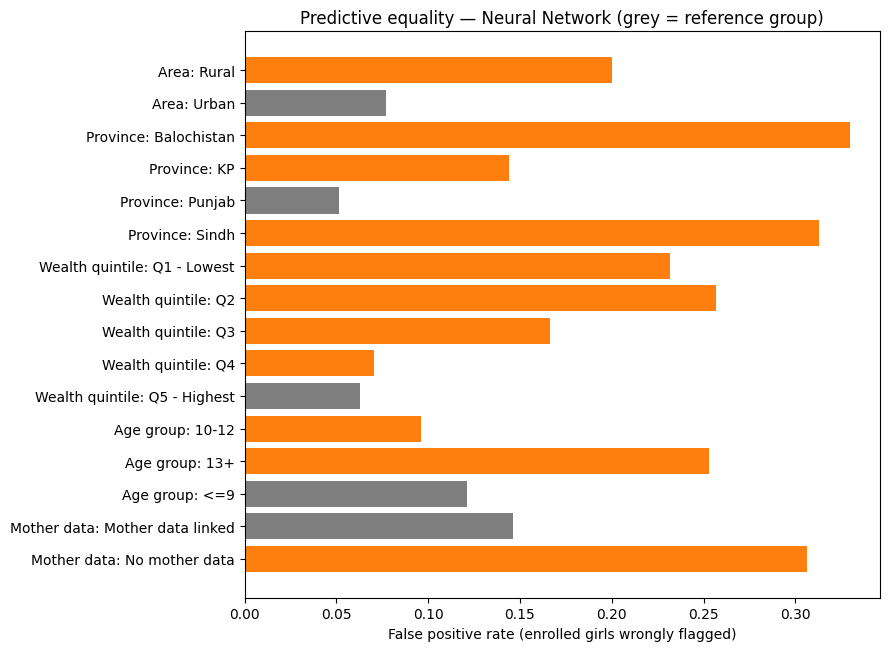

In [32]:
# ============================================================
# STEP 5: PREDICTIVE EQUALITY (False Positive Rate across groups)
# ============================================================

pe_rows = []
for attr in SENSITIVE:
    t = group_table(attr)
    ref = t.loc[REF[attr]]
    for g, r in t.iterrows():
        pe_rows.append({
            "Attribute": attr, "Group": g, "n": int(r["n"]),
            "Reference": "yes" if g == REF[attr] else "",
            "FPR": r["FPR"],
            "FPR diff vs ref": r["FPR"] - ref["FPR"],
            "FPR ratio vs ref": r["FPR"] / ref["FPR"] if ref["FPR"] > 0 else np.nan,
            "False alarms (FP)": int(r["FP"]),
        })
pe_df = pd.DataFrame(pe_rows)
print(f"Predictive equality — {PRIMARY_MODEL}")
display(pe_df.round(3))

plot_df = pe_df[pe_df["Group"] != "Unknown"].copy()
plot_df["label"] = plot_df["Attribute"] + ": " + plot_df["Group"].astype(str)
fig, ax = plt.subplots(figsize=(9, 0.32 * len(plot_df) + 1.5))
ax.barh(plot_df["label"], plot_df["FPR"],
        color=np.where(plot_df["Reference"] == "yes", "tab:gray", "tab:orange"))
ax.set_xlabel("False positive rate (enrolled girls wrongly flagged)")
ax.set_title(f"Predictive equality — {PRIMARY_MODEL} (grey = reference group)")
ax.invert_yaxis(); plt.tight_layout(); plt.show()

**Interpretation.** Enrolled girls in disadvantaged groups are wrongly flagged far more often. The FPR is 0.20 for rural girls versus 0.08 for urban girls (2.6x), 0.33 in Balochistan and 0.31 in Sindh versus 0.05 in Punjab (about 6x), 0.23 and 0.26 in the two poorest quintiles versus 0.06 in Q5, and 0.25 for ages 13+ versus 0.12 for the reference age group (0.10 for ages 10-12). All gaps are statistically real except Q4 and ages 10-12.

**Statistical check on the gaps (household bootstrap)**

In [33]:
# ============================================================
# STEP 6: ARE THE GAPS REAL? HOUSEHOLD-LEVEL BOOTSTRAP (95% CI)
# ============================================================
# Resample whole households (sisters stay together), recompute gaps vs the reference group.
N_BOOT = 1000
rng = np.random.default_rng(42)

y_arr = audit["y_true"].values
p_arr = audit[f"pred_{PRIMARY_MODEL}"].values
hh_uniq, hh_inv = np.unique(groups_test.values, return_inverse=True)
order = np.argsort(hh_inv, kind="stable")
hh_rows = np.split(order, np.cumsum(np.bincount(hh_inv))[:-1])

def metrics_by_code(code, k, idx):
    c, y, p = code[idx], y_arr[idx], p_arr[idx]
    cnt = np.bincount(c, minlength=k).astype(float)
    pos = np.bincount(c, weights=y, minlength=k)
    neg = cnt - pos
    sel = np.bincount(c, weights=p, minlength=k) / np.where(cnt > 0, cnt, np.nan)
    tpr = np.bincount(c, weights=p * y, minlength=k) / np.where(pos > 0, pos, np.nan)
    fpr = np.bincount(c, weights=p * (1 - y), minlength=k) / np.where(neg > 0, neg, np.nan)
    return sel, tpr, fpr

boot_rows = []
for attr in SENSITIVE:
    cats = pd.Categorical(audit[attr])
    code, names = cats.codes, list(cats.categories)
    k, r = len(names), names.index(REF[attr])
    full = metrics_by_code(code, k, np.arange(len(audit)))
    draws = []
    for _ in range(N_BOOT):
        pick = rng.integers(0, len(hh_rows), len(hh_rows))
        idx = np.concatenate([hh_rows[i] for i in pick])
        sel, tpr, fpr = metrics_by_code(code, k, idx)
        draws.append(np.vstack([sel / sel[r], tpr - tpr[r], fpr - fpr[r]]))
    draws = np.array(draws)                       # (N_BOOT, 3, k)
    lo = np.nanpercentile(draws, 2.5, axis=0)
    hi = np.nanpercentile(draws, 97.5, axis=0)
    for j, g in enumerate(names):
        if g == REF[attr] or g == "Unknown":
            continue
        pt = (full[0][j] / full[0][r], full[1][j] - full[1][r], full[2][j] - full[2][r])
        boot_rows.append({
            "Attribute": attr, "Group": g,
            "DI ratio": pt[0], "DI 95% CI": f"[{lo[0][j]:.2f}, {hi[0][j]:.2f}]",
            "DI differs from 1?": "yes" if (lo[0][j] > 1 or hi[0][j] < 1) else "no",
            "TPR gap": pt[1], "TPR gap 95% CI": f"[{lo[1][j]:.2f}, {hi[1][j]:.2f}]",
            "TPR gap real?": "yes" if (lo[1][j] > 0 or hi[1][j] < 0) else "no",
            "FPR gap": pt[2], "FPR gap 95% CI": f"[{lo[2][j]:.2f}, {hi[2][j]:.2f}]",
            "FPR gap real?": "yes" if (lo[2][j] > 0 or hi[2][j] < 0) else "no",
        })
boot_df = pd.DataFrame(boot_rows)
print(f"Gaps vs reference group with 95% household-bootstrap CIs — {PRIMARY_MODEL}")
display(boot_df.round(3))

Gaps vs reference group with 95% household-bootstrap CIs — Neural Network


,Attribute,Group,DI ratio,DI 95% CI,DI differs from 1?,TPR gap,TPR gap 95% CI,TPR gap real?,FPR gap,FPR gap 95% CI,FPR gap real?
0,Area,Rural,2.534,"[2.19, 2.96]",yes,0.226,"[0.15, 0.28]",yes,0.123,"[0.10, 0.15]",yes
1,Province,Balochistan,4.111,"[3.50, 4.86]",yes,0.279,"[0.20, 0.36]",yes,0.278,"[0.22, 0.34]",yes
2,Province,KP,1.811,"[1.50, 2.18]",yes,0.033,"[-0.05, 0.11]",no,0.093,"[0.06, 0.13]",yes
3,Province,Sindh,4.073,"[3.57, 4.70]",yes,0.349,"[0.28, 0.41]",yes,0.261,"[0.22, 0.30]",yes
4,Wealth quintile,Q1 - Lowest,3.155,"[2.52, 4.04]",yes,0.279,"[0.18, 0.39]",yes,0.169,"[0.12, 0.22]",yes
5,Wealth quintile,Q2,3.069,"[2.47, 3.99]",yes,0.223,"[0.12, 0.33]",yes,0.194,"[0.15, 0.24]",yes
6,Wealth quintile,Q3,2.019,"[1.59, 2.65]",yes,0.078,"[-0.04, 0.19]",no,0.103,"[0.07, 0.14]",yes
7,Wealth quintile,Q4,1.119,"[0.86, 1.50]",no,0.011,"[-0.11, 0.14]",no,0.007,"[-0.02, 0.04]",no
8,Age group,10-12,0.873,"[0.76, 0.99]",yes,-0.064,"[-0.13, -0.01]",yes,-0.026,"[-0.05, 0.00]",no
9,Age group,13+,2.039,"[1.84, 2.26]",yes,0.236,"[0.18, 0.29]",yes,0.131,"[0.10, 0.17]",yes


**Interpretation.** Most gaps are larger than sampling noise. The TPR gap is statistically real for rural girls (0.23, CI 0.15 to 0.28), Sindh (0.35), Balochistan (0.28), the two poorest wealth quintiles (Q1 0.28, Q2 0.22), girls aged 13+ (0.24) and girls with no mother data (0.16, CI 0.06 to 0.26). Girls aged 10-12 have a significantly lower TPR than the reference (-0.06, CI -0.13 to -0.01). Three TPR gaps cannot be separated from zero: KP, Q3 and Q4. Two FPR gaps cannot either: Q4 and ages 10-12. Q4 is the clearest "no gap" case: its DI of 1.12 passes the 80% rule and its interval (0.86 to 1.50) includes 1. The no-mother-data group has only 190 test girls, so its estimates are wide and should be read as indicative only. The intervals reflect test-set sampling (households resampled together), not variation from retraining the model.

**Cross-model comparison**

In [34]:
# ============================================================
# STEP 7: CROSS-MODEL FAIRNESS COMPARISON
# ============================================================
cmp_df = pd.DataFrame([attr_summary(a, m)
                       for m in audit_models for a in SENSITIVE])
print("Fairness gaps for every model (threshold = 0.5)")
display(cmp_df.round(3))

# Average gaps across attributes, one row per model
display(cmp_df.groupby("Model")[["TPR range (equal opp. gap)", "FPR range",
                                 "Equalized-odds gap (max)", "Overall accuracy"]]
        .mean().round(3))

Fairness gaps for every model (threshold = 0.5)


,Attribute,Model,TPR range (equal opp. gap),FPR range,Equalized-odds gap (max),Min/Max flag-rate ratio,Overall accuracy
0,Area,Logistic Regression,0.283,0.168,0.283,0.297,0.747
1,Province,Logistic Regression,0.553,0.395,0.553,0.123,0.747
2,Wealth quintile,Logistic Regression,0.441,0.206,0.441,0.250,0.747
3,Age group,Logistic Regression,0.300,0.148,0.300,0.398,0.747
4,Mother data,Logistic Regression,0.166,0.187,0.187,0.547,0.747
5,Area,Decision Tree,0.219,0.136,0.219,0.411,0.746
6,Province,Decision Tree,0.432,0.315,0.432,0.218,0.746
7,Wealth quintile,Decision Tree,0.369,0.221,0.369,0.307,0.746
8,Age group,Decision Tree,0.257,0.142,0.257,0.489,0.746
9,Mother data,Decision Tree,0.141,0.114,0.141,0.623,0.746


,TPR range (equal opp. gap),FPR range,Equalized-odds gap (max),Overall accuracy
Model,,,,
Decision Tree,0.284,0.186,0.284,0.746
Logistic Regression,0.349,0.221,0.353,0.747
Neural Network,0.263,0.182,0.263,0.766
Random Forest,0.280,0.137,0.280,0.768


**Interpretation.** All four models show the same pattern, so the bias is not specific to the Neural Network. The average equalized-odds gap is 0.263 for the Neural Network, 0.280 for the Random Forest, 0.284 for the Decision Tree and 0.353 for Logistic Regression. Accuracy ranges from 0.746 to 0.768. For every model, province has the largest TPR gap (0.35 to 0.55) and mother-data status the smallest (0.08 to 0.17). The average gap changes by at most 0.09 between models, while the gaps between groups within a single model reach 0.35 to 0.55 for province, so switching models would not remove the disparities. They come mainly from the features and the data.

The Neural Network was used for the detailed audit because it had the highest recall and F1 in the benchmarking, which was run on the same test set. To make sure that choice does not drive the conclusions, all four models are audited here.

**Fairness-accuracy trade-off analysis**

Fairness is enforced with group-specific decision thresholds, which are learned on out-of-fold training predictions so that the test set stays untouched. A mixing weight (lambda) moves each group's threshold from the single global threshold of 0.5 (lambda = 0, unconstrained) to the group threshold at which that group's TPR (equal opportunity) or flag rate (demographic parity) matches the overall training level (lambda = 1). Each lambda gives one (fairness gap, accuracy) point on the test set, and the Pareto frontier keeps the points for which no other point has both a smaller gap and a higher accuracy.

In [35]:
# ============================================================
# STEP 8: FAIRNESS–ACCURACY TRADE-OFF — OUT-OF-FOLD TRAINING PROBABILITIES
# ============================================================

oof_prob = cross_val_predict(
    clone(audit_models[PRIMARY_MODEL]), X_tr(PRIMARY_MODEL), y_train,
    groups=groups_train,
    cv=StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42),
    method="predict_proba", n_jobs=-1
)[:, 1]

print("Out-of-fold probabilities computed:", oof_prob.shape)

Out-of-fold probabilities computed: (20245,)


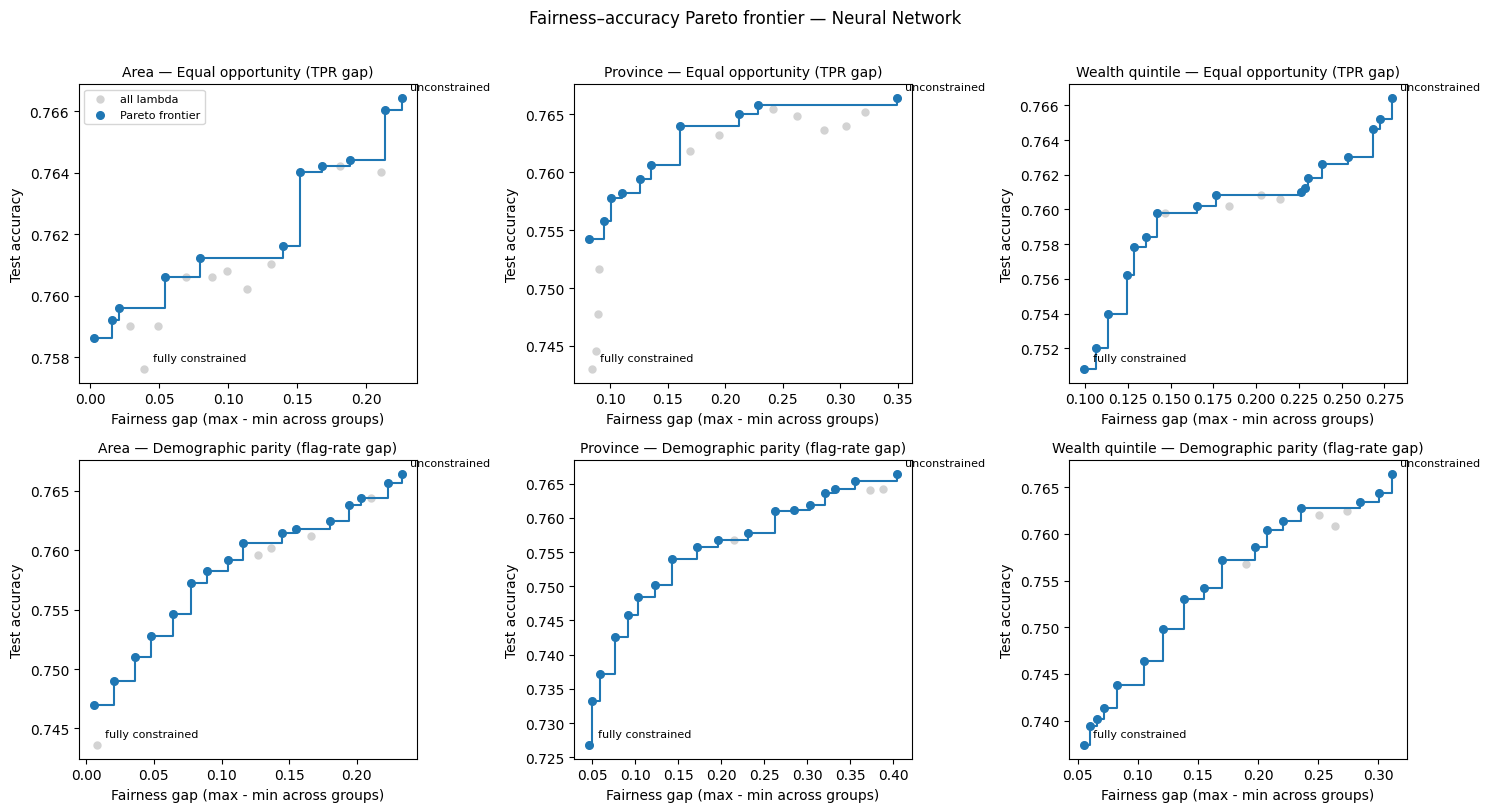

Price of fairness (lambda = 0 vs lambda = 1), test set


,Attribute,Constraint,Gap before,Gap after,Accuracy before,Accuracy after,Accuracy change (pp),Recall before,Recall after,FPR before,FPR after
0,Area,Demographic parity (flag-rate gap),0.233,0.008,0.766,0.744,-2.284,0.608,0.577,0.151,0.170
1,Area,Equal opportunity (TPR gap),0.226,0.039,0.766,0.758,-0.881,0.608,0.617,0.151,0.169
2,Province,Demographic parity (flag-rate gap),0.404,0.047,0.766,0.727,-3.966,0.608,0.556,0.151,0.184
3,Province,Equal opportunity (TPR gap),0.349,0.084,0.766,0.743,-2.344,0.608,0.600,0.151,0.182
4,Wealth quintile,Demographic parity (flag-rate gap),0.311,0.055,0.766,0.737,-2.905,0.608,0.570,0.151,0.176
5,Wealth quintile,Equal opportunity (TPR gap),0.279,0.100,0.766,0.751,-1.562,0.608,0.606,0.151,0.174


In [36]:
# ============================================================
# STEP 9: PARETO FRONTIER — ENFORCING FAIRNESS vs ACCURACY
# ============================================================


# Method: group-specific decision thresholds (post-processing).
# threshold_g(lam) = (1 - lam) * 0.5 + lam * t_g
#   lam = 0 -> one global threshold (unconstrained)
#   lam = 1 -> each group's threshold set (on training data) so that its TPR
#              (equal opportunity) or flag rate (demographic parity) matches the
#              overall unconstrained level
# Sweeping lam from 0 to 1 traces accuracy against the fairness gap.


THR_GRID = np.linspace(0.01, 0.99, 99)
LAMBDAS  = np.linspace(0, 1, 21)
CONSTRAINTS = {"Equal opportunity (TPR gap)": "tpr",
               "Demographic parity (flag-rate gap)": "sel"}
FRONT_ATTRS = ["Area", "Province", "Wealth quintile"]

p_test = audit[f"prob_{PRIMARY_MODEL}"].values
y_te   = audit["y_true"].values
y_tr   = y_train.values

def metric_value(pred, y, metric):
    if metric == "tpr":
        return pred[y == 1].mean() if (y == 1).any() else np.nan
    return pred.mean()

def find_threshold(prob, y, target, metric):
    pred = prob[:, None] >= THR_GRID[None, :]
    if metric == "tpr":
        vals = pred[y == 1].mean(axis=0) if (y == 1).any() else np.full(len(THR_GRID), np.nan)
    else:
        vals = pred.mean(axis=0)
    if np.all(np.isnan(vals)):
        return THRESHOLD
    return THR_GRID[np.nanargmin(np.abs(vals - target))]

def gap_of(pred, y, g, metric):
    vals = []
    for grp in np.unique(g):
        m = g == grp
        if grp == "Unknown" or m.sum() < MIN_N:
            continue
        v = metric_value(pred[m], y[m], metric)
        if not np.isnan(v):
            vals.append(v)
    return max(vals) - min(vals)

def pareto_mask(gap, acc):
    keep, best = np.zeros(len(gap), bool), -np.inf
    for i in np.lexsort((-acc, gap)):      # smallest gap first, ties: highest accuracy
        if acc[i] > best + 1e-12:
            keep[i], best = True, acc[i]
    return keep

front_rows = []
for attr in FRONT_ATTRS:
    g_tr, g_te = s_train[attr].values, s_test[attr].values
    for cname, metric in CONSTRAINTS.items():
        base_pred = (oof_prob >= THRESHOLD).astype(int)
        target = metric_value(base_pred, y_tr, metric)       # overall level on training data
        t_g = {}
        for grp in np.unique(g_tr):
            m = g_tr == grp
            if m.sum() >= MIN_N and grp != "Unknown":
                t_g[grp] = find_threshold(oof_prob[m], y_tr[m], target, metric)
        for lam in LAMBDAS:
            thr_map = {grp: (1 - lam) * THRESHOLD + lam * t for grp, t in t_g.items()}
            thr = np.array([thr_map.get(grp, THRESHOLD) for grp in g_te])
            pred = (p_test >= thr).astype(int)
            front_rows.append({
                "Attribute": attr, "Constraint": cname, "lambda": lam,
                "Fairness gap": gap_of(pred, y_te, g_te, metric),
                "Accuracy": (pred == y_te).mean(),
                "Recall": pred[y_te == 1].mean(),
                "FPR": pred[y_te == 0].mean(),
                "Precision": y_te[pred == 1].mean() if pred.sum() else np.nan,
            })
front_df = pd.DataFrame(front_rows)
front_df["On Pareto frontier"] = False
for (a, c), d in front_df.groupby(["Attribute", "Constraint"]):
    front_df.loc[d.index, "On Pareto frontier"] = pareto_mask(
        d["Fairness gap"].values, d["Accuracy"].values)

# Plot: accuracy vs fairness gap (one panel per attribute x constraint)
fig, axes = plt.subplots(len(CONSTRAINTS), len(FRONT_ATTRS),
                         figsize=(5 * len(FRONT_ATTRS), 4 * len(CONSTRAINTS)))
for i, cname in enumerate(CONSTRAINTS):
    for j, attr in enumerate(FRONT_ATTRS):
        ax = axes[i, j]
        d = front_df[(front_df["Attribute"] == attr) & (front_df["Constraint"] == cname)]
        f = d[d["On Pareto frontier"]].sort_values("Fairness gap")
        ax.scatter(d["Fairness gap"], d["Accuracy"], c="lightgray", s=25, label="all lambda")
        ax.step(f["Fairness gap"], f["Accuracy"], where="post", color="tab:blue")
        ax.scatter(f["Fairness gap"], f["Accuracy"], color="tab:blue", s=30, label="Pareto frontier")
        for lam, tag in [(0, "unconstrained"), (1, "fully constrained")]:
            r = d[d["lambda"] == lam].iloc[0]
            ax.annotate(tag, (r["Fairness gap"], r["Accuracy"]),
                        textcoords="offset points", xytext=(6, 6), fontsize=8)
        ax.set_title(f"{attr} — {cname}", fontsize=10)
        ax.set_xlabel("Fairness gap (max - min across groups)"); ax.set_ylabel("Test accuracy")
axes[0, 0].legend(fontsize=8)
plt.suptitle(f"Fairness–accuracy Pareto frontier — {PRIMARY_MODEL}", y=1.01)
plt.tight_layout(); plt.show()

# Price of fairness: unconstrained vs fully constrained
rows = []
for (a, c), d in front_df.groupby(["Attribute", "Constraint"]):
    u, f1 = d[d["lambda"] == 0].iloc[0], d[d["lambda"] == 1].iloc[0]
    rows.append({
        "Attribute": a, "Constraint": c,
        "Gap before": u["Fairness gap"], "Gap after": f1["Fairness gap"],
        "Accuracy before": u["Accuracy"], "Accuracy after": f1["Accuracy"],
        "Accuracy change (pp)": (f1["Accuracy"] - u["Accuracy"]) * 100,
        "Recall before": u["Recall"], "Recall after": f1["Recall"],
        "FPR before": u["FPR"], "FPR after": f1["FPR"],
    })
tradeoff_df = pd.DataFrame(rows)
print("Price of fairness (lambda = 0 vs lambda = 1), test set")
display(tradeoff_df.round(3))

Equal-opportunity thresholds, all attributes — Neural Network (test set)


,Attribute,TPR gap before,TPR gap after,FPR gap before,FPR gap after,EO gap before,EO gap after,Accuracy change (pp),Recall before,Recall after,Extra girls reached (TP),Extra false alarms (FP)
0,Area,0.226,0.039,0.123,0.007,0.226,0.039,-0.881,0.608,0.617,14,58
1,Province,0.349,0.084,0.278,0.052,0.349,0.084,-2.344,0.608,0.600,-15,102
2,Wealth quintile,0.279,0.100,0.194,0.066,0.279,0.100,-1.562,0.608,0.606,-4,74
3,Age group,0.300,0.007,0.157,0.025,0.300,0.025,-0.401,0.608,0.611,5,25
4,Mother data,0.161,0.052,0.160,0.078,0.161,0.078,-0.040,0.608,0.603,-10,-8


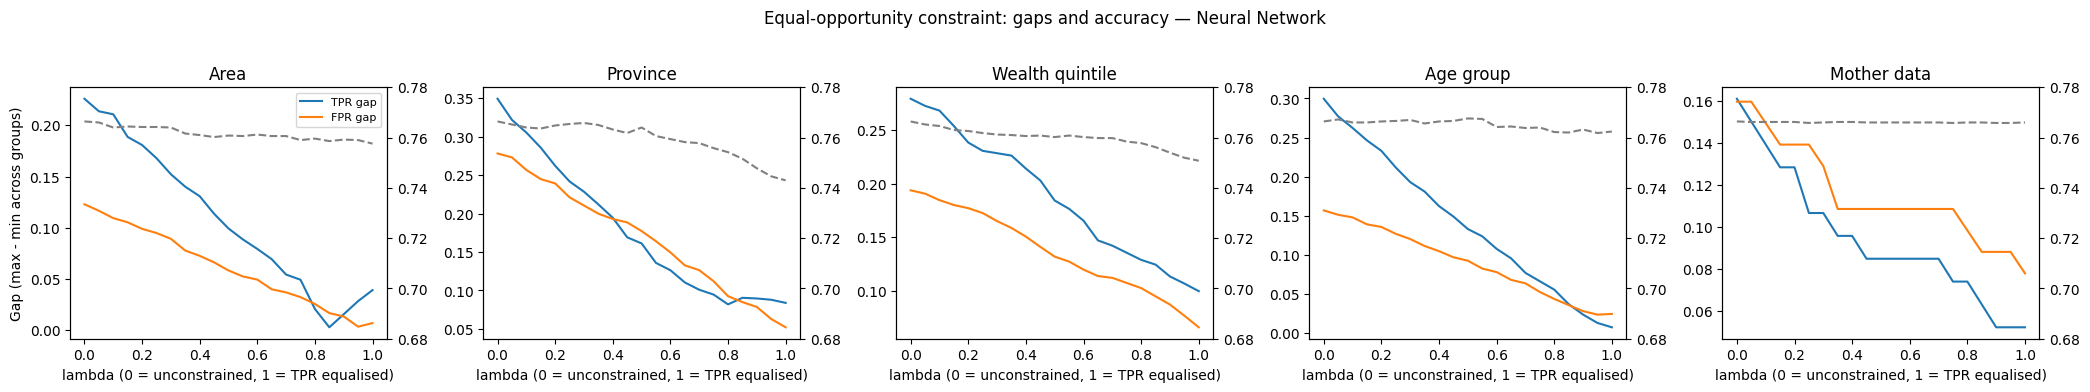

In [37]:
# ============================================================
# STEP 10: EXTENDED TRADE-OFF — ALL FIVE ATTRIBUTES, ALL GAPS TRACKED
# ============================================================

# Same method as Step 9 (equal-opportunity thresholds learned on out-of-fold training
# predictions), but now for every sensitive attribute, and tracking TPR gap, FPR gap,
# equalized-odds gap, accuracy and resource use at each lambda.

tpr_fn = lambda p, y: p[y == 1].mean() if (y == 1).any() else np.nan
fpr_fn = lambda p, y: p[y == 0].mean() if (y == 0).any() else np.nan
sel_fn = lambda p, y: p.mean()

def spread(pred, y, g, fn):
    vals = []
    for grp in np.unique(g):
        m = g == grp
        if grp == "Unknown" or m.sum() < MIN_N:
            continue
        v = fn(pred[m], y[m])
        if not np.isnan(v):
            vals.append(v)
    return max(vals) - min(vals)

base_pred = (oof_prob >= THRESHOLD).astype(int)
tpr_target = tpr_fn(base_pred, y_tr)          # overall TPR on training data

ext_rows = []
for attr in SENSITIVE:
    g_tr, g_te = s_train[attr].values, s_test[attr].values
    t_g = {}
    for grp in np.unique(g_tr):
        m = g_tr == grp
        if m.sum() >= MIN_N and grp != "Unknown":
            t_g[grp] = find_threshold(oof_prob[m], y_tr[m], tpr_target, "tpr")
    for lam in LAMBDAS:
        thr = np.array([(1 - lam) * THRESHOLD + lam * t_g.get(grp, THRESHOLD)
                        for grp in g_te])
        pred = (p_test >= thr).astype(int)
        tg, fg = spread(pred, y_te, g_te, tpr_fn), spread(pred, y_te, g_te, fpr_fn)
        ext_rows.append({
            "Attribute": attr, "lambda": lam,
            "TPR gap": tg, "FPR gap": fg, "Equalized-odds gap": max(tg, fg),
            "Flag-rate gap": spread(pred, y_te, g_te, sel_fn),
            "Accuracy": (pred == y_te).mean(), "Recall": pred[y_te == 1].mean(),
            "TP": int(((pred == 1) & (y_te == 1)).sum()),
            "FP": int(((pred == 1) & (y_te == 0)).sum()),
        })
ext_df = pd.DataFrame(ext_rows)

# Before (lambda = 0) vs after (lambda = 1), for every attribute
rows = []
for a, d in ext_df.groupby("Attribute", sort=False):
    u, f = d[d["lambda"] == 0].iloc[0], d[d["lambda"] == 1].iloc[0]
    rows.append({
        "Attribute": a,
        "TPR gap before": u["TPR gap"], "TPR gap after": f["TPR gap"],
        "FPR gap before": u["FPR gap"], "FPR gap after": f["FPR gap"],
        "EO gap before": u["Equalized-odds gap"], "EO gap after": f["Equalized-odds gap"],
        "Accuracy change (pp)": (f["Accuracy"] - u["Accuracy"]) * 100,
        "Recall before": u["Recall"], "Recall after": f["Recall"],
        "Extra girls reached (TP)": int(f["TP"] - u["TP"]),
        "Extra false alarms (FP)": int(f["FP"] - u["FP"]),
    })
ext_table = pd.DataFrame(rows)
print(f"Equal-opportunity thresholds, all attributes — {PRIMARY_MODEL} (test set)")
display(ext_table.round(3))

# Plot: how every gap and the accuracy move as the constraint is tightened
fig, axes = plt.subplots(1, len(SENSITIVE), figsize=(4.2 * len(SENSITIVE), 3.8))
for ax, (a, d) in zip(axes, ext_df.groupby("Attribute", sort=False)):
    ax.plot(d["lambda"], d["TPR gap"], label="TPR gap", color="tab:blue")
    ax.plot(d["lambda"], d["FPR gap"], label="FPR gap", color="tab:orange")
    ax.set_title(a); ax.set_xlabel("lambda (0 = unconstrained, 1 = TPR equalised)")
    ax2 = ax.twinx()
    ax2.plot(d["lambda"], d["Accuracy"], "--", color="gray", label="Accuracy")
    ax2.set_ylim(0.68, 0.78)
axes[0].set_ylabel("Gap (max - min across groups)")
axes[0].legend(loc="upper right", fontsize=8)
plt.suptitle(f"Equal-opportunity constraint: gaps and accuracy — {PRIMARY_MODEL}", y=1.02)
plt.tight_layout(); plt.show()

**Trade-off results and recommendation.** Enforcing equal opportunity (equal TPR across groups) closes most of the gap at a small accuracy cost:

- Age group: TPR gap 0.300 to 0.007 for -0.4 pp accuracy (+25 false alarms)
- Area: 0.226 to 0.039 for -0.9 pp (+58 false alarms)
- Wealth quintile: 0.279 to 0.100 for -1.6 pp (+74 false alarms)
- Province: 0.349 to 0.084 for -2.3 pp (+102 false alarms)
- Mother data: 0.161 to 0.052 for -0.04 pp, but only 190 girls, so the estimate is unreliable

Equalising TPR also narrows the FPR gaps (area 0.123 to 0.007, province 0.278 to 0.052, wealth 0.194 to 0.066, age 0.157 to 0.025, mother data 0.160 to 0.078). The equalized-odds gap after adjustment is set by whichever of the TPR and FPR gaps is larger. Recall stays at about 0.60 to 0.62, and the adjustment finds no meaningful number of additional out-of-school girls (-15 to +14 true positives in the test set). It mainly moves flags between groups. The accuracy cost therefore comes from extra false alarms: the largest, 102 for province, is about 3% of the 3,281 enrolled girls in the test set. Overall FPR rises from 0.151 to between 0.169 and 0.182 for area, province and wealth.

Enforcing demographic parity is worse for the main objective. Recall falls from 0.608 to 0.556 (province), 0.570 (wealth) and 0.577 (area), and accuracy drops by 2.3 to 4.0 pp. Equal opportunity is therefore the more suitable constraint.

After full adjustment a gap of 0.04 to 0.10 remains for area, province and wealth, because the thresholds are learned on training predictions and do not transfer perfectly to the test set. The values above are read at lambda = 1 and were not tuned on the test set.

**Limits of this fix.** Group-specific thresholds use the protected attribute at decision time (disparate treatment), and equalising TPR means lowering the threshold for lower-need groups (urban, Punjab, Q5, ages 10-12), which spends support on girls with a lower out-of-school rate. These are policy choices, not only statistical ones. The adjusted thresholds are also computed one attribute at a time, so they cannot be applied for several attributes at once without a new analysis.

**Recommendation.** Do not use group-specific thresholds to decide about individual girls or households. Use the model for area- and programme-level targeting, as set out in the ethical evaluation, and monitor TPR by area, province, wealth quintile and age group. Where the programme chooses to reduce missed girls, age, area and wealth are the cheapest places to do it (-0.4, -0.9 and -1.6 pp of accuracy, with 25 to 74 extra false alarms each), for example by adding outreach for 10-12-year-old, urban, Punjab and better-off girls. Province is the most expensive (-2.3 pp and 102 extra false alarms). The more fundamental fix is to add the variables the model cannot see: school availability and quality, safety, and distance to school measured for all girls, including those who never enrolled. The infrastructure variables added in Milestone 4 improved risk ranking only modestly and did not remove the disparities.

In [38]:
# MILESTONE 4 — FAIRNESS RE-AUDIT: OLD NN @0.5 vs NEW MODEL @ chosen threshold
p_new = final_model_v2.predict_proba(X2_test)[:, 1]
pred_new = (p_new >= FINAL_THR).astype(int)
pred_old = audit[f"pred_{PRIMARY_MODEL}"].values
y_te_arr = y_test.values

def tpr_fpr(y, p):
    return (p[y == 1].mean() if (y == 1).any() else np.nan,
            p[y == 0].mean() if (y == 0).any() else np.nan)

rows = []
for attr in SENSITIVE:
    g = s_test[attr].values
    for grp in np.unique(g):
        m = g == grp
        if grp == "Unknown" or m.sum() < MIN_N:
            continue
        t_o, f_o = tpr_fpr(y_te_arr[m], pred_old[m])
        t_n, f_n = tpr_fpr(y_te_arr[m], pred_new[m])
        rows.append({"Attribute": attr, "Group": grp, "n": int(m.sum()),
                     "TPR old": t_o, "TPR new": t_n, "FPR old": f_o, "FPR new": f_n})
reaudit = pd.DataFrame(rows)
display(reaudit.round(3))

gaps = (reaudit.groupby("Attribute")
        .agg(**{"TPR gap old": ("TPR old", lambda s: s.max() - s.min()),
                "TPR gap new": ("TPR new", lambda s: s.max() - s.min()),
                "FPR gap old": ("FPR old", lambda s: s.max() - s.min()),
                "FPR gap new": ("FPR new", lambda s: s.max() - s.min())}))
display(gaps.round(3))
print(f"Accuracy: old {np.mean(pred_old == y_te_arr):.3f} -> new {np.mean(pred_new == y_te_arr):.3f}")
print(f"Recall:   old {recall_score(y_te_arr, pred_old):.3f} -> new {recall_score(y_te_arr, pred_new):.3f}")

,Attribute,Group,n,TPR old,TPR new,FPR old,FPR new
0,Area,Rural,3340,0.655,0.956,0.200,0.637
1,Area,Urban,1652,0.429,0.869,0.077,0.398
2,Province,Balochistan,607,0.697,0.973,0.330,0.807
3,Province,KP,1055,0.450,0.930,0.144,0.658
4,Province,Punjab,1995,0.418,0.859,0.052,0.402
5,Province,Sindh,1335,0.767,0.976,0.313,0.634
6,Wealth quintile,Q1 - Lowest,1009,0.732,0.989,0.232,0.790
7,Wealth quintile,Q2,1089,0.676,0.948,0.257,0.627
8,Wealth quintile,Q3,1083,0.531,0.928,0.166,0.601
9,Wealth quintile,Q4,946,0.464,0.905,0.070,0.474


,TPR gap old,TPR gap new,FPR gap old,FPR gap new
Attribute,,,,
Age group,0.300,0.051,0.157,0.141
Area,0.226,0.087,0.123,0.239
Mother data,0.161,0.042,0.160,0.387
Province,0.349,0.117,0.278,0.406
Wealth quintile,0.279,0.144,0.194,0.512


Accuracy: old 0.766 -> new 0.622
Recall:   old 0.608 -> new 0.938


Switching to the class-weighted XGBoost model and lowering the threshold to 0.25 raises recall from 0.608 to 0.938 and shrinks every equal-opportunity gap (area 0.226 to 0.087, province 0.349 to 0.117, wealth 0.279 to 0.144, age 0.300 to 0.051, mother data 0.161 to 0.042). The groups the earlier model missed most benefit most: urban TPR rises from 0.429 to 0.869, Punjab from 0.418 to 0.859 and Q5 from 0.453 to 0.845. The cost is accuracy (0.766 to 0.622) and false alarms: overall FPR is 0.543, and FPR gaps widen for area (0.123 to 0.239), province (0.278 to 0.406), wealth (0.194 to 0.512) and mother-data status (0.160 to 0.387), while the age gap narrows slightly (0.157 to 0.141). Equal opportunity therefore improves while predictive equality worsens. This comparison changes both the model (Neural Network to XGBoost) and the threshold (0.5 to 0.25), so the improvement cannot be credited to the threshold alone. The threshold is a programme decision about how many false alarms a budget can absorb, not only a statistical choice.

In [39]:
# =============================================================================
# MILESTONE 4 — REPRESENTATIVENESS: SURVEY-WEIGHTED METRICS
# =============================================================================
print([c for c in model_data.columns if re.search(r"weight|wgt|wt$", c, re.I)])
WEIGHT_COL = "weight"

assert WEIGHT_COL in model_data.columns, f"Column '{WEIGHT_COL}' not found in model_data."

w = pd.to_numeric(model_data.loc[X_test.index, WEIGHT_COL], errors="coerce").fillna(0).values
one = np.ones(len(y_te_arr))

def rates(y, p, wt):
    tp = wt[(y == 1) & (p == 1)].sum(); fn = wt[(y == 1) & (p == 0)].sum()
    fp = wt[(y == 0) & (p == 1)].sum(); tn = wt[(y == 0) & (p == 0)].sum()
    return {"Out-of-school rate": wt[y == 1].sum() / wt.sum(),
            "Accuracy": (tp + tn) / wt.sum(),
            "Recall (TPR)": tp / (tp + fn) if tp + fn else np.nan,
            "FPR": fp / (fp + tn) if fp + tn else np.nan}

print(f"{FINAL_NAME}, threshold {FINAL_THR:.2f}")
display(pd.DataFrame({"Unweighted": rates(y_te_arr, pred_new, one),
                      "Survey-weighted": rates(y_te_arr, pred_new, w)}).T.round(3))

wrows = []
for attr in ["Area", "Province", "Wealth quintile", "Age group"]:
    g = s_test[attr].values
    for grp in np.unique(g):
        m = g == grp
        if grp == "Unknown" or m.sum() < MIN_N:
            continue
        ru, rw = rates(y_te_arr[m], pred_new[m], one[m]), rates(y_te_arr[m], pred_new[m], w[m])
        wrows.append({"Attribute": attr, "Group": grp,
                      "TPR unweighted": ru["Recall (TPR)"], "TPR weighted": rw["Recall (TPR)"],
                      "FPR unweighted": ru["FPR"], "FPR weighted": rw["FPR"]})
display(pd.DataFrame(wrows).round(3))

['weight']
XGBoost (weighted), threshold 0.25


,Out-of-school rate,Accuracy,Recall (TPR),FPR
Unweighted,0.343,0.622,0.938,0.543
Survey-weighted,0.288,0.627,0.923,0.492


,Attribute,Group,TPR unweighted,TPR weighted,FPR unweighted,FPR weighted
0,Area,Rural,0.956,0.943,0.637,0.605
1,Area,Urban,0.869,0.844,0.398,0.331
2,Province,Balochistan,0.973,0.980,0.807,0.797
3,Province,KP,0.930,0.944,0.658,0.694
4,Province,Punjab,0.859,0.847,0.402,0.385
5,Province,Sindh,0.976,0.973,0.634,0.554
6,Wealth quintile,Q1 - Lowest,0.989,0.986,0.790,0.751
7,Wealth quintile,Q2,0.948,0.930,0.627,0.568
8,Wealth quintile,Q3,0.928,0.909,0.601,0.555
9,Wealth quintile,Q4,0.905,0.890,0.474,0.430


**MILESTONE 4 ETHICAL EVALUATION**

**Intended use.** The model should support area- and programme-level targeting, such as deciding which districts or schools receive enrolment drives, stipends or new school places. It should not be used to label, rank or make decisions about individual girls or families. The fairness audit shows why: even after tuning, the model misses out-of-school girls in some groups (urban, Punjab, wealthier, ages 10-12) far more often than in others, so an individual flag or non-flag is unreliable. The group-specific thresholds tested above use protected attributes at decision time, so they are an auditing tool and should not be used to decide about individual households.

**Avoiding blame.** Low maternal education is the strongest predictor, but it is a structural disadvantage that policy should address through adult literacy, school access and stipends. It must not be presented as the mothers' fault or as a failing of the household. Results should be reported as "girls in areas with low maternal education need more support", not as "uneducated mothers cause dropout".

**Privacy.** Only aggregated results should be shared. The HIES microdata must stay on secured storage with restricted access, and the data-minimisation choices from Section 1 are kept (for example, the reproductive-health modules remain archived and are not used as predictors). Subgroup results are reported only for groups above the minimum size (n >= 50), to avoid identifying individuals in small cells.

**Representativeness.** The final model was evaluated with and without HIES survey weights (see the weighted table above). Survey weights lower the out-of-school rate from 0.343 to 0.288, so the sample over-represents out-of-school girls. Weighted recall (0.923) and accuracy (0.627) are close to the unweighted values (0.938, 0.622), and weighted FPR is lower (0.492 vs 0.543). Weighted TPR gaps are somewhat larger than unweighted ones (for example wealth 0.178 vs 0.144, province 0.133 vs 0.117, area 0.099 vs 0.087, age 0.081 vs 0.051), so population-level disparities are larger than in the sample. Models were trained on unweighted data, so population-level claims rest on the weighted evaluation, not on the training fit.

**Correlation, not causation.** The data are cross-sectional. The findings show which girls are at risk, not what causes them to be out of school. Interaction effects (H2, H4) and infrastructure effects describe associations; testing whether a stipend or a nearer school changes enrolment needs an intervention or a causal design.

**MILESTONE 4 — PART C: FEATURE IMPORTANCE AND RESEARCH INSIGHTS**

Feature importance for the final model is measured with permutation importance on the held-out test set: each predictor is shuffled in turn and the drop in ROC-AUC is recorded. Permutation importance works on the original variables (not the one-hot columns), is computed on data the model never saw, and can be compared across model types. Infrastructure variables are highlighted to show what Milestone 4 added.

Permutation importance — XGBoost (weighted)


,Feature,Drop in ROC-AUC,SD,Infrastructure
1,mom_educ_level,0.1046,0.0052,False
2,s1aq51,0.0481,0.0020,False
3,province,0.0256,0.0017,False
4,wealth_index,0.0145,0.0018,False
5,has_electricity,0.0140,0.0012,True
6,toilet_group,0.0117,0.0013,True
7,mom_age,0.0092,0.0008,False
8,hh_size,0.0058,0.0006,False
9,mom_employed,0.0028,0.0005,False
10,rural,0.0017,0.0006,False


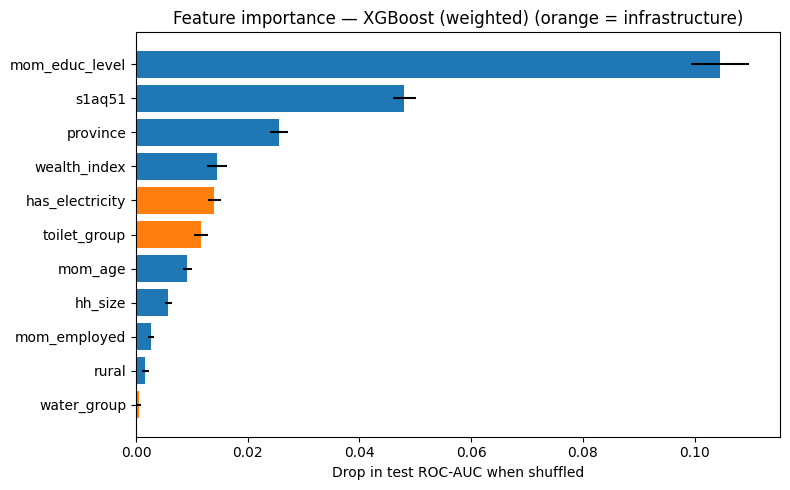

,n,out_of_school_rate
has_electricity,,
0.0,3658,0.665
1.0,16587,0.275


,n,out_of_school_rate
water_group,,
improved,18519,0.340
other/unmapped,81,0.432
surface,282,0.550
unimproved,1363,0.376


,n,out_of_school_rate
toilet_group,,
improved,16801,0.282
none,2036,0.695
other/unmapped,178,0.522
unimproved,1230,0.611


In [43]:

pi = permutation_importance(final_model_v2, X2_test, y_test, scoring="roc_auc",
                            n_repeats=10, random_state=42, n_jobs=-1)

imp = (pd.DataFrame({"Feature": X2_test.columns,
                     "Drop in ROC-AUC": pi.importances_mean,
                     "SD": pi.importances_std})
       .sort_values("Drop in ROC-AUC", ascending=False).reset_index(drop=True))
imp["Infrastructure"] = imp["Feature"].isin(INFRA_NUM + INFRA_BIN + INFRA_CAT)
imp.index += 1
print(f"Permutation importance — {FINAL_NAME}")
display(imp.round(4))

s = imp.sort_values("Drop in ROC-AUC")
plt.figure(figsize=(8, 5))
plt.barh(s["Feature"], s["Drop in ROC-AUC"], xerr=s["SD"],
         color=np.where(s["Infrastructure"], "tab:orange", "tab:blue"))
plt.xlabel("Drop in test ROC-AUC when shuffled")
plt.title(f"Feature importance — {FINAL_NAME} (orange = infrastructure)")
plt.tight_layout()
plt.show()

# out-of-school rate by each infrastructure variable (training data)
for c in INFRA_BIN + INFRA_CAT:
    display(model_data.iloc[train_idx].groupby(c)["out_of_school"]
            .agg(n="count", out_of_school_rate="mean").round(3))

**Interpretation of permutation importance.** Permutation importance asks: if one feature is randomly shuffled in the test set (breaking its link to the outcome), how much worse does the model get at telling out-of-school girls from enrolled ones? A bigger drop in ROC-AUC means the model relies on that feature more. The model is the class-weighted XGBoost (scale_pos_weight), not a survey-weighted model.

Maternal education is the dominant predictor: shuffling it reduced test ROC-AUC by 0.105 (SD 0.005), more than twice the drop from any other feature. This is strong support for the maternal-education hypothesis in predictive terms. The girl's age (0.048) and province (0.026) are next, followed by a cluster of household-condition variables with similar, modest contributions: wealth index (0.015), electricity (0.014) and toilet type (0.012). Maternal age and household size contribute little, and maternal employment (0.003), rural residence (0.002) and drinking-water source (0.001) add almost nothing.

Descriptive comparisons on the training data show that infrastructure deprivation is strongly associated with non-enrolment. Girls in households without electricity were out of school at more than twice the rate of those with electricity (66.5% vs 27.5%), and out-of-school rates rose from 28.2% with improved sanitation to 69.5% with no toilet facility. Differences by water source were small, apart from a higher rate among the small group relying on surface water (55.0%, n = 282). The contrast between these large bivariate gaps and the modest permutation importances suggests that electricity and sanitation largely capture household deprivation already reflected in wealth, region and maternal education. Likewise, the low importance of rural residence should not be read as an absence of rural-urban differences: permutation importance splits credit among correlated predictors, and rurality is closely tied to province and infrastructure access. These results are predictive associations and do not identify causal effects.

**FATEN PRINCIPLES CHECK**

The final model is XGBoost (weighted) at a threshold of 0.25, chosen on training folds to maximise F2. On the test set, it catches 93.8% of out-of-school girls (106 missed out of 1,711) but wrongly flags 1,780 enrolled girls, a false positive rate of 0.543.

**Fairness.** The model's error rates differ across groups. The earlier Neural Network at the default 0.5 threshold caught 65.5% of out-of-school rural girls but only 42.9% of urban girls, and 76.7% in Sindh against 41.8% in Punjab. The final XGBoost model at a threshold of 0.25 narrows every equal-opportunity gap (area 0.226 to 0.087, province 0.349 to 0.117, wealth 0.279 to 0.144, age 0.300 to 0.051), although the comparison changes both the model and the threshold. The model therefore meets equal opportunity well but not predictive equality, so it is partially meeting this principle.

**Autonomy.** The model is not making any decisions about individuals. It will only guide which districts, schools or outreach teams receive support, not which families are judged or required to act. Families will be free to decline support without penalty, and no benefit would depend on a model score.

**Trust.** The pipeline is reproducible: it uses fixed random states, a household-grouped train/test split and a threshold chosen only on training folds, and every result is documented. However, XGBoost is less interpretable than logistic regression. Permutation importance and survey-weighted results help explain the model and show how far it applies to the population, but a plain-language summary would be needed before real use.

**Equity.** The model directs support to the groups with the highest need: rural girls, the poorest quintiles, Sindh, Balochistan and girls aged 13+, matching their actual out-of-school rates. The 0.25 threshold also favours girls with the most to lose, since missing an out-of-school girl is costlier than a false alarm. Its blind spot is out-of-school girls in better-off and urban groups, who are still caught less often (TPR 0.845 in Q5 vs 0.989 in Q1).

**Non-maleficence.** The main risk is stigma from false alarms if flags reach families, teachers or communities. This risk is highest in Balochistan (FPR 0.807) and among girls with no linked mother data (0.918). It is reduced by avoiding individual-level decisions, reporting only aggregated results for groups of at least 50, not framing low maternal education as the mothers' fault, and keeping the reproductive-health modules out of the model.


### **Real life scenario**

The provincial education department, district officers and an NGO would test the model in a few districts. They would use household survey data, similar to HIES, to identify areas where girls are more likely to drop out of school. Based on this information, they would decide where to provide stipends, organise enrolment campaigns and build new schools. After one year, they would compare these districts with similar districts where the model was not used to see whether more girls had returned to school.

### Stakeholders

Girls and their families are the most directly affected because the model determines where support is provided. Mothers, specifically, are also important because their education level is a major factor in predicting girls' school enrolment. Teachers may face increased student numbers. Field workers are responsible for following the model's recommendations. The education department decides how the model is used, and community leaders influence whether families accept these initiatives.

### Expected performance

The model is expected to identify approximately one enrolled girl for every out-of-school girl found. On the test set, the model correctly flagged 1,605 out-of-school girls but also wrongly flagged 1,780 enrolled girls, so about half of all outreach visits would reach girls who are already in school.

### Failure modes

The model may fail to identify many out-of-school girls, particularly in urban areas, Punjab, wealthier households and girls aged 10–12. It may also wrongly identify girls as being at risk in Balochistan, Sindh and the poorest households, wasting resources and reducing public trust.

Another problem is that the model may leave Migrant and remote households out because they are not properly represented in the HIES survey. Moreover, areas identified as low-risk may receive less attention, meaning that problems in those areas remain unnoticed. There is also a risk that household data could be misused to monitor or punish families.

### Governance safeguards

The model should only identify high-risk areas, not label individual girls or families. Field workers should verify information before taking action and should be allowed to correct the model's decisions. Its performance should be regularly checked across different regions and income groups to identify unfair results.

Some outreach resources should also be reserved for areas the model identifies as low-risk, so that girls who were missed can still receive support. Data should be collected with consent, kept secure and shared only in summary form. Families should have the right to correct incorrect information. The model should be updated with new survey data and independently reviewed regularly.

### Preventing digital marginalisation

The biggest concern is that girls who are missing from survey data may also be ignored by education policies. Therefore, the model should never be the only way girls can access support. Schools, lady health workers and community organisations should also be able to refer girls who need help.

The department should identify gaps in its data, such as households where information about mothers is missing. Future surveys should also collect information about distance to schools, girls' safety and the availability of schools. These factors can help explain why some girls are unable to attend school and improve the model's accuracy.